<div align="center" style="text-align: center; padding: 60px 0;">

<h1 style="text-align: center;">Forecasting US Clothing Store Sales</h1>

<br>

<h2 style="text-align: center;">Time Series Analysis</h2>

<br><br>

<p style="text-align: center; font-size: 18px;"><b>Author:</b> Adrien Letort</p>

<p style="text-align: center; font-size: 18px;">2026</p>

</div>


# Introduction

In this notebook, we analyze a time series and forecast it with two different methods.

In the first approach, we apply an ETS decomposition to split the series into its trend, seasonal and residual components. The trend and seasonality are extrapolated, while the residual $R_t$ is modeled with an ARIMA model. We then recombine the three components to obtain the final forecast and compare it with the test set.

The second approach uses Facebook Prophet, a more automated method, to produce the same forecast.

Finally, we compare both approaches using error metrics and draw conclusions.


# 0. Dataset
First of all, we need to find a suitable time series (TS). For the analysis to make sense, the TS should have three distinct components: trend, seasonality and residual.

Retail sales are a natural candidate: they grow with the economy and prices (trend) and follow the calendar (seasonality). Clothing is one of the most seasonal retail categories, with a very strong peak at Christmas.

We use the [MRTSSM448USN](https://fred.stlouisfed.org/series/MRTSSM448USN) series from FRED (Federal Reserve Bank of St. Louis): the monthly sales of clothing and clothing accessories stores in the United States, in millions of dollars, **not seasonally adjusted**. The source is the Monthly Retail Trade Survey of the US Census Bureau. The seasonal adjustment must not be applied, otherwise the seasonal component we want to study would already be removed.


## 0.1. Import dataset
Let's start by loading the dataset into a pandas DataFrame.

The file `MRTSSM448USN.csv` has two columns: `observation_date` (first day of the month) and `MRTSSM448USN` (sales in millions of dollars). It contains 415 monthly observations, from January 1992 to July 2026. We check that there is no missing value, and we set an explicit monthly frequency (`MS`, month start) on the index, which statsmodels needs.


In [1]:
import pandas as pd

raw = pd.read_csv("MRTSSM448USN.csv", parse_dates=["observation_date"], index_col="observation_date")

# Monthly sales of clothing stores, in millions of dollars (not seasonally adjusted)
df = raw.rename(columns={"MRTSSM448USN": "sales"})
df.index.name = "date"
print(f"Missing values: {df['sales'].isna().sum()}")
# Explicit monthly frequency (month start), needed by statsmodels
df = df.asfreq("MS")

df

Missing values: 0


,sales
date,
1992-01-01,6734
1992-02-01,7302
1992-03-01,8245
1992-04-01,9152
1992-05-01,9294
...,...
2026-03-01,26690
2026-04-01,25869
2026-05-01,29282


## 0.2. Plot TS

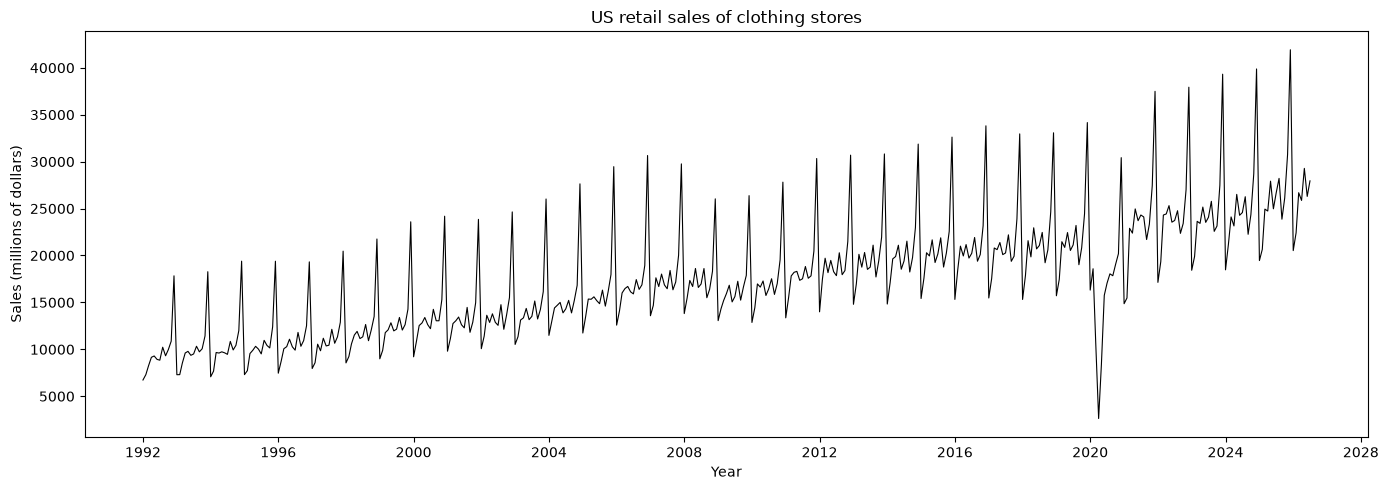

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df.sales, color="black", linewidth=0.8)
ax.set_title("US retail sales of clothing stores")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions of dollars)")
plt.tight_layout()
plt.show()

> Seasonality?

The series shows a very regular yearly pattern: a sharp peak every December, a low in January and February, and smaller bumps in spring. The seasonal swings get bigger as the series grows.

> Trend?

The average monthly level grows from about 9 700 million dollars in 1992 to about 25 300 in 2024. There are two clear breaks: the 2008-2009 financial crisis, and above all the **COVID-19 shock in spring 2020**, when sales fell to 2 631 million in April 2020 (about 87% below April 2019), before a quick rebound in 2021.


## 0.3. train-test split
To compute the errors between our forecast and reality, we have to keep a part of the data to test our result. We keep the year 2025 plus the first seven months of 2026 as test set. The train set contains only complete years, which is convenient for the yearly windows used later.

Train-set: January 1992 -> December 2024 (396 months, 33 years)

Test-set: January 2025 -> July 2026 (19 months)


In [3]:
df_train = df.loc[:"2024-12-01"]
df_test = df.loc["2025-01-01":]

print(f"Train: {df_train.index.min():%Y-%m} -> {df_train.index.max():%Y-%m} ({len(df_train)} months)")
print(f"Test:  {df_test.index.min():%Y-%m} -> {df_test.index.max():%Y-%m} ({len(df_test)} months)")

Train: 1992-01 -> 2024-12 (396 months)
Test:  2025-01 -> 2026-07 (19 months)


# 1. ETS Decomposition + ARIMA
We will perform the ETS Decomposition. Our decomposition/recomposition will follow the next steps:
1. Determine the model (additive or multiplicative)
1. Determine if there is a trend component (Anova test)
1. Estimate the trend using CMA (Center Moving Average)
1. Detrend
1. Determine if there is a seasonal component (Anova test)
1. Forecast St and ensure area conservation is met
1. Remove seasonality, $Y_t' = R_t \cdot T_t$
1. Compute and forecast the trend (method varies depending on linearity)
1. Remove trend, $Y_t'' = R_t$
1. Forecast R_t using ARIMA model
1. Recomposition
1. Error's measurement


## 1.1. Additive or Multiplicative

In [4]:
import statsmodels.api as sm

# One window per calendar year = one full seasonal cycle (12 months), on the train set only
windows = df_train["sales"].groupby(df_train.index.year).agg(mean="mean", std="std", n="size")
windows = windows[windows["n"] == 12]

# Fit Std = a * mean + b + e
X = sm.add_constant(windows["mean"])
ols = sm.OLS(windows["std"], X).fit()
print(ols.summary().tables[1])

# t-test on H0: a = 0 at the 5% level
alpha = 0.05
a_hat = ols.params["mean"]
t_stat = ols.tvalues["mean"]
p_value = ols.pvalues["mean"]
print(f"\na = {a_hat:.4f}, t = {t_stat:.3f}, p-value = {p_value:.2e}")
if p_value < alpha:
    print("H0 rejected: the std grows with the level -> multiplicative model")
else:
    print("H0 not rejected: the std does not depend on the level -> additive model")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1705.4076    429.037      3.975      0.000     830.380    2580.435
mean           0.1358      0.024      5.580      0.000       0.086       0.185

a = 0.1358, t = 5.580, p-value = 4.07e-06
H0 rejected: the std grows with the level -> multiplicative model


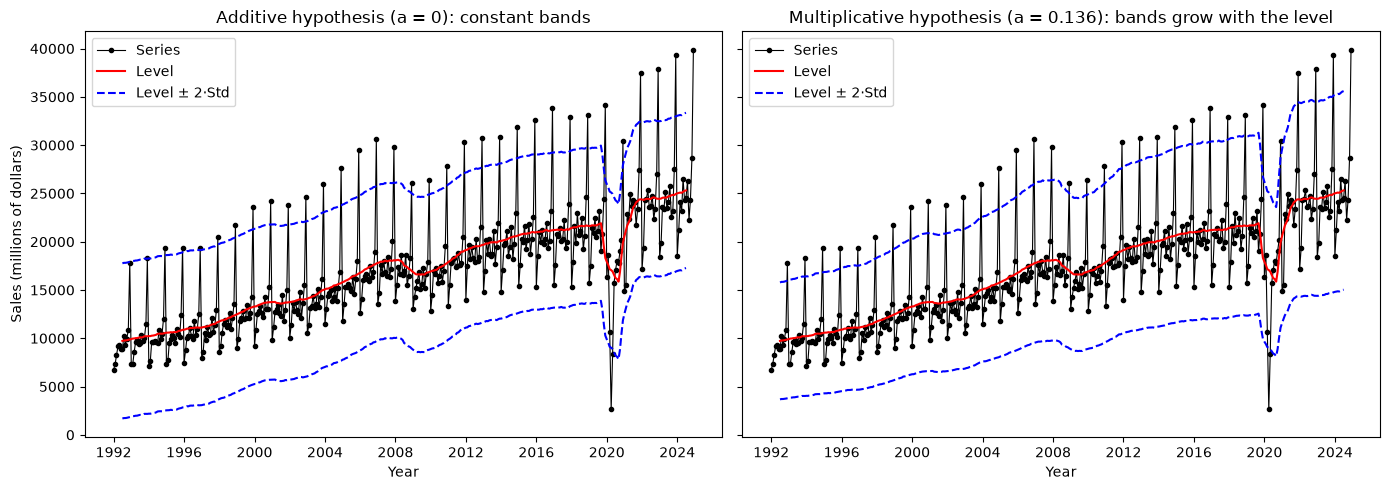

In [5]:
k = 2  # band half-width, in number of standard deviations

# Level: 12-month centered moving average
level = df_train["sales"].rolling(12, center=True).mean()

# Additive hypothesis (a = 0): constant spread, equal to the average yearly std
std_add = windows["std"].mean()
# Multiplicative hypothesis: spread proportional to the level, from the fit Std = a * mean + b
std_mult = ols.params["mean"] * level + ols.params["const"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
bands = [
    (axes[0], std_add, "Additive hypothesis (a = 0): constant bands"),
    (axes[1], std_mult, f"Multiplicative hypothesis (a = {a_hat:.3f}): bands grow with the level"),
]
for ax, spread, title in bands:
    ax.plot(df_train.index, df_train["sales"], color="black", marker=".", linewidth=0.8, label="Series")
    ax.plot(level.index, level, color="red", label="Level")
    ax.plot(level.index, level + k * spread, color="blue", linestyle="--", label=f"Level ± {k}·Std")
    ax.plot(level.index, level - k * spread, color="blue", linestyle="--")
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Sales (millions of dollars)")
plt.tight_layout()
plt.show()

> Additive or multiplicative ?

The t-test rejects $a = 0$ ($a = 0.136$, $t = 5.58$, p-value $= 4 \times 10^{-6}$). The yearly standard deviation grows with the yearly mean: when clothing stores sell more, the gap between December and January grows with them. Graphically, the bands of the multiplicative hypothesis (right) follow the series, while the constant bands (left) are too wide at the beginning and too narrow at the end.

TS's model: $Y_t = T_t \cdot S_t \cdot R_t$

In business terms, the seasonal effect is a **percentage** of the activity ("December is +66% above the average month"), not a fixed amount of dollars.


## 1.2. Trend Component

### 1.2.1. Is there a trend ?
We'll perform an Anova test on the average monthly sales per year to determine if there is a trend or not.


month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1992,6734.0,7302.0,8245.0,9152.0,9294.0,8930.0,8846.0,10226.0,9311.0,9974.0,10876.0,17834.0,9727.0
1993,7297.0,7306.0,8531.0,9610.0,9787.0,9364.0,9511.0,10331.0,9735.0,10060.0,11430.0,18272.0,10103.0
1994,7077.0,7676.0,9661.0,9607.0,9736.0,9629.0,9467.0,10846.0,9936.0,10434.0,12003.0,19396.0,10456.0
1995,7306.0,7731.0,9552.0,9902.0,10323.0,10024.0,9514.0,10961.0,10417.0,10151.0,12401.0,19390.0,10639.0
1996,7460.0,8734.0,10066.0,10286.0,11082.0,10267.0,9915.0,11803.0,10327.0,10936.0,12514.0,19321.0,11059.0
1997,7959.0,8577.0,10551.0,9851.0,11182.0,10364.0,10442.0,12134.0,10649.0,11331.0,12894.0,20463.0,11366.0
1998,8556.0,9231.0,10572.0,11521.0,11914.0,11149.0,11334.0,12647.0,10922.0,12075.0,13504.0,21757.0,12098.0
1999,8993.0,9897.0,11781.0,12081.0,12833.0,11968.0,12150.0,13398.0,12053.0,12628.0,14282.0,23590.0,12971.0
2000,9206.0,10875.0,12535.0,12815.0,13393.0,12638.0,12199.0,14264.0,13046.0,13046.0,15299.0,24187.0,13625.0


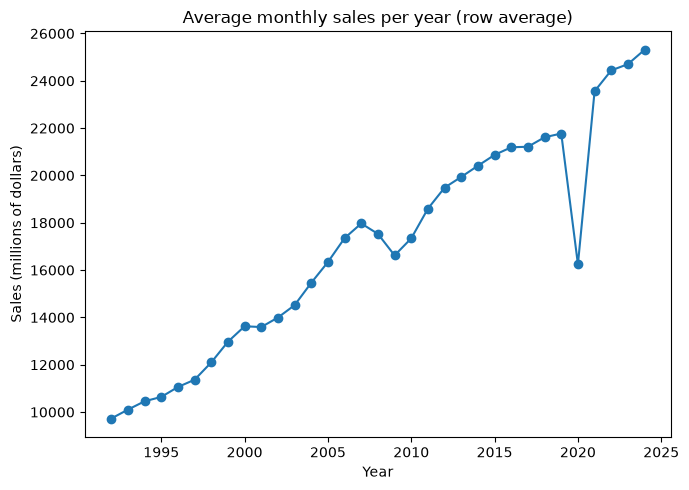

In [6]:
# Buys-Ballot table on the train set: years as rows, months as columns
long = pd.DataFrame(
    {"sales": df_train["sales"], "year": df_train.index.year, "month": df_train.index.month}
)
table = long.pivot(index="year", columns="month", values="sales")

year_mean = table.mean(axis=1)  # average by row
month_mean = table.mean(axis=0)  # average by column

# Display the table with the averages as margins
display_table = table.copy()
display_table["Average"] = year_mean
display_table.loc["Average"] = pd.concat([month_mean, pd.Series({"Average": table.stack().mean()})])
display(display_table.round(0))

fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(year_mean.index, year_mean, marker="o")
axes.set_title("Average monthly sales per year (row average)")
axes.set_xlabel("Year")
axes.set_ylabel("Sales (millions of dollars)")
plt.tight_layout()
plt.show()

In [7]:
import statsmodels.formula.api as smf

# Two-way Anova on the Buys-Ballot table (year + month factors, no interaction).
# The month factor absorbs the seasonality, so the year factor tests
# H0: all yearly means are equal (no trend) against H1: at least one differs.
anova_fit = smf.ols("sales ~ C(year) + C(month)", data=long).fit()
anova = sm.stats.anova_lm(anova_fit)
print(anova)

f_year = anova.loc["C(year)", "F"]
p_year = anova.loc["C(year)", "PR(>F)"]
print(f"\nYear factor: F = {f_year:.2f}, p-value = {p_year:.2e}")
if p_year < alpha:
    print("H0 rejected: the yearly means differ -> there is a trend")
else:
    print("H0 not rejected: the yearly means are equal -> no trend")

             df        sum_sq       mean_sq           F         PR(>F)
C(year)    32.0  8.212041e+09  2.566263e+08  147.153117  4.310552e-183
C(month)   11.0  5.524669e+09  5.022426e+08  287.992993  1.633765e-168
Residual  352.0  6.138671e+08  1.743940e+06         NaN            NaN

Year factor: F = 147.15, p-value = 4.31e-183
H0 rejected: the yearly means differ -> there is a trend


> Is there a trend ?

The row averages grow from about 9 700 million dollars per month in 1992 to about 25 300 in 2024, with two visible dips: 2009 (financial crisis) and 2020 (COVID). The column averages show the seasonal profile, with the highest values in spring and December.

The two-way Anova rejects H0 for the year factor ($F = 147$, p-value far below 5%): the yearly means are not all equal, so **there is a trend component** in the series. Note that the month factor is also very significant ($F = 288$), which announces the seasonality.


### 1.2.2. Estimate the trend
To do so, we'll compute a CMA(12) to obtain a smooth trend. We choose 12 because it is the number of components in a year (12 months).


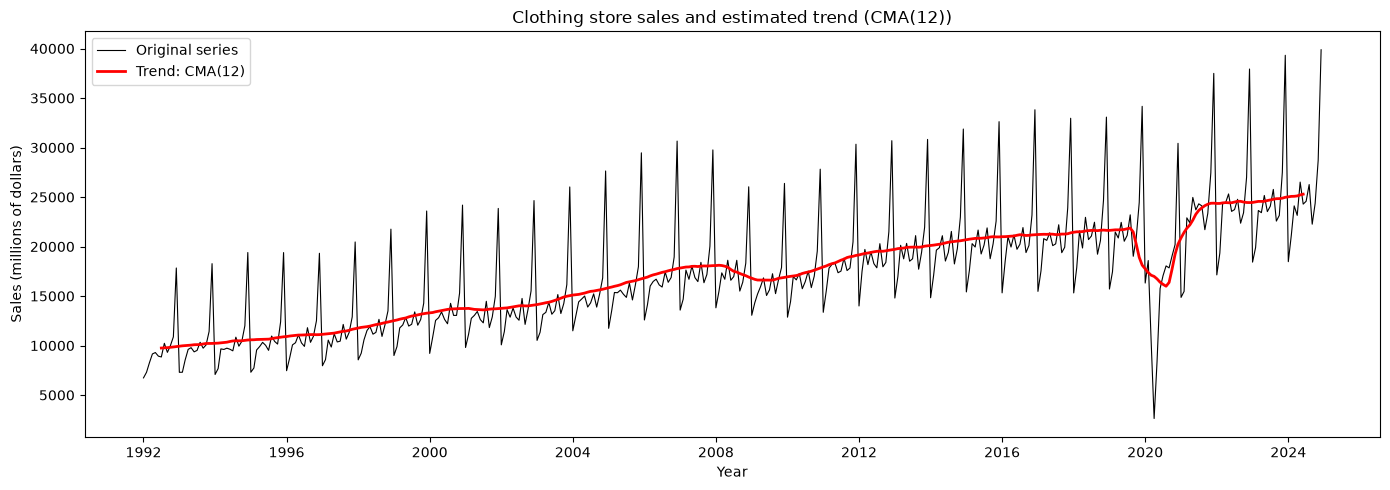

In [8]:
# CMA(12): the order is even, so a plain 12-month window is not centered on a month.
# We use a 2x12 moving average, i.e. weights [1/24, 1/12, ..., 1/12, 1/24] over 13 months,
# which is centered on month t and covers exactly one year.
# The first and last 6 months have no CMA value.
cma = df_train["sales"].rolling(12).mean().rolling(2).mean().shift(-6)
df_train = df_train.assign(cma=cma)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["sales"], color="black", linewidth=0.8, label="Original series")
ax.plot(df_train.index, df_train["cma"], color="red", linewidth=2, label="Trend: CMA(12)")
ax.set_title("Clothing store sales and estimated trend (CMA(12))")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> Trend

The red line is our estimated trend. It has been obtained with a CMA(12) on the original Time Series. Doing that, we lose the 6 first points and the 6 last points. This is not a problem because we still have more than 380 points to compute our average by season.

The CMA follows the long-term growth, the 2009 slowdown, and the COVID collapse of 2020 (a 12-month average is pulled down for a whole year by a single extreme month). This will slightly contaminate the seasonal coefficients of the months around 2020.


### 1.2.3. Detrend
We will remove the trend to our original Time Series to be able to decompose the seasonal component. If the model is multiplicative we divide the original TS by the estimated trend, otherwise we subtract it (see section 1.1 for the choice of the model).


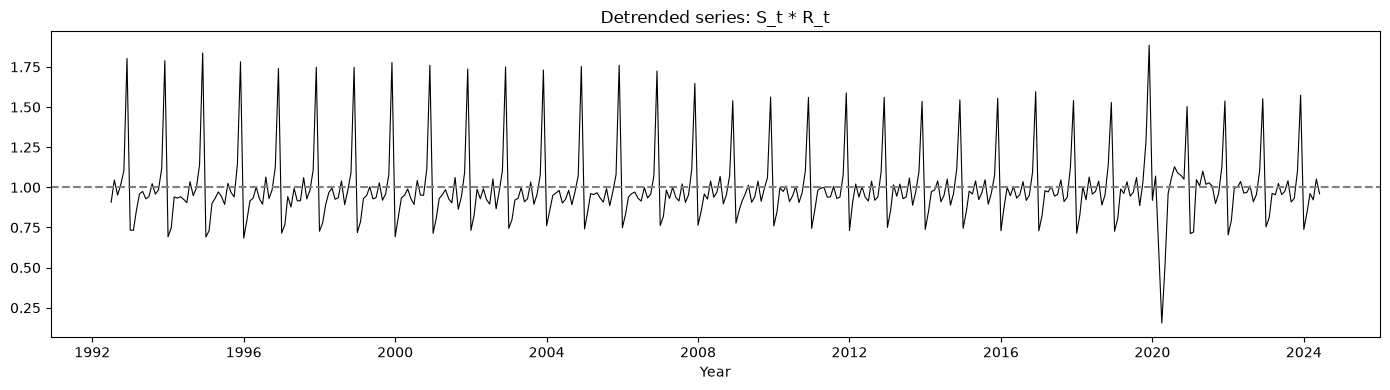

In [9]:
# Multiplicative model: Y_t / T_t = S_t * R_t
# The CMA is NaN for the first and last 6 months, so the ratio is NaN there too
df_train = df_train.assign(seasonal_residual=df_train["sales"] / df_train["cma"])

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_train.index, df_train.seasonal_residual, color="black", linewidth=0.8)
ax.axhline(1, color="grey", linestyle="--")
ax.set_title("Detrended series: S_t * R_t")
ax.set_xlabel("Year")
plt.tight_layout()
plt.show()

## 1.3. Seasonal Component

### 1.3.1. Is there a seasonal component ?
We'll perform an Anova test on the average of the detrended series per month to determine if there is a seasonal component or not.


month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1992,NaN,NaN,NaN,NaN,NaN,NaN,0.907,1.046,0.951,1.016,1.103,1.802,1.138
1993,0.734,0.733,0.853,0.959,0.974,0.929,0.942,1.023,0.958,0.985,1.120,1.789,1.000
1994,0.692,0.749,0.940,0.933,0.942,0.925,0.905,1.035,0.949,0.995,1.141,1.837,1.004
1995,0.691,0.730,0.900,0.933,0.972,0.942,0.894,1.025,0.968,0.940,1.144,1.782,0.993
1996,0.684,0.797,0.916,0.933,1.002,0.928,0.895,1.064,0.930,0.984,1.128,1.740,1.000
1997,0.715,0.768,0.943,0.878,0.993,0.916,0.917,1.060,0.928,0.982,1.108,1.748,0.996
1998,0.727,0.780,0.891,0.967,0.996,0.926,0.935,1.040,0.892,0.981,1.091,1.748,0.998
1999,0.718,0.787,0.931,0.949,1.004,0.928,0.936,1.028,0.920,0.959,1.081,1.778,1.002
2000,0.692,0.815,0.934,0.951,0.990,0.929,0.894,1.042,0.952,0.951,1.114,1.761,1.002


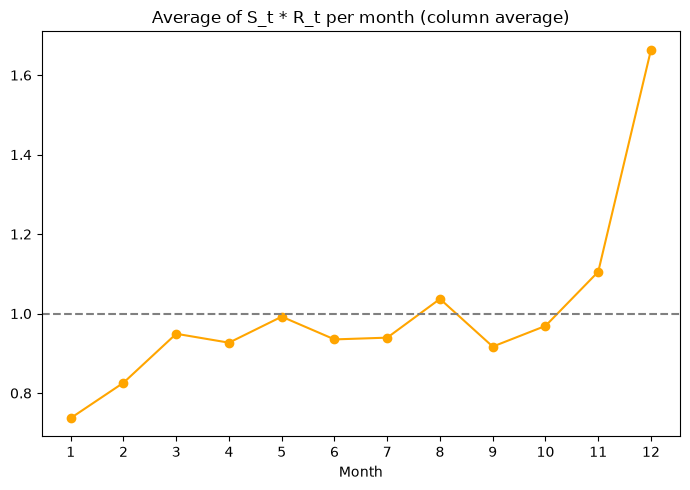

In [10]:
# Buys-Ballot table of the detrended series (S_t * R_t): years as rows, months as columns
# The first 6 and last 6 months are NaN (no CMA value), so they are dropped
detrended = df_train["seasonal_residual"].dropna()
long_s = pd.DataFrame(
    {"seasonal_residual": detrended, "year": detrended.index.year, "month": detrended.index.month}
)
table_s = long_s.pivot(index="year", columns="month", values="seasonal_residual")

year_mean_s = table_s.mean(axis=1)  # average by row
month_mean_s = table_s.mean(axis=0)  # average by column

# Display the table with the averages as margins
display_table_s = table_s.copy()
display_table_s["Average"] = year_mean_s
display_table_s.loc["Average"] = pd.concat([month_mean_s, pd.Series({"Average": table_s.stack().mean()})])
display(display_table_s.round(3))

fig, axes = plt.subplots(1, 1, figsize=(7, 5))
axes.plot(month_mean_s.index, month_mean_s, marker="o", color="orange")
axes.axhline(1, color="grey", linestyle="--")
axes.set_title("Average of S_t * R_t per month (column average)")
axes.set_xlabel("Month")
axes.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

In [11]:
# One-way Anova with the month as factor, on the detrended series.
# H0: all monthly means are equal (no seasonality) against H1: at least one differs.
anova_s_fit = smf.ols("seasonal_residual ~ C(month)", data=long_s).fit()
anova_s = sm.stats.anova_lm(anova_s_fit)
print(anova_s)

f_month = anova_s.loc["C(month)", "F"]
p_month = anova_s.loc["C(month)", "PR(>F)"]
print(f"\nMonth factor: F = {f_month:.2f}, p-value = {p_month:.2e}")
if p_month < alpha:
    print("H0 rejected: the monthly means differ -> there is a seasonal component")
else:
    print("H0 not rejected: the monthly means are equal -> no seasonal component")

             df     sum_sq   mean_sq           F         PR(>F)
C(month)   11.0  18.441306  1.676482  333.440159  4.699769e-185
Residual  372.0   1.870355  0.005028         NaN            NaN

Month factor: F = 333.44, p-value = 4.70e-185
H0 rejected: the monthly means differ -> there is a seasonal component


> Is there a seasonal component ?

The column averages show a clear seasonal profile. December is far above the trend (about 1.66), while January (0.74) and February (0.83) are far below it. Spring and August sit around or just above the trend, September is a low month (0.92).

The Anova test rejects H0 ($F = 333$, p-value far below 5%): the monthly means are not all equal, so **there is a seasonal component** in the series.

The average of the averages is 0.9999, very close to 1 but not exactly. We therefore implement the area conservation explicitly in the next section.


### 1.3.2. Forecast and area conservation
We almost forecast our seasonal component, but we need to ensure the area conservation is met: the 12 seasonal coefficients must average exactly 1 (multiplicative model).


In [12]:
# Area conservation: divide each monthly average by the average of averages,
# so that the 12 seasonal coefficients average exactly 1 (sum = 12)
average_of_average = month_mean_s.mean()
seasonal_coef = month_mean_s / average_of_average

# New row in the matrix with the seasonal coefficients
display_table_s.loc["Seasonal coefficient"] = pd.concat(
    [seasonal_coef, pd.Series({"Average": seasonal_coef.mean()})]
)
display(display_table_s.round(3))

print(f"Average of averages before correction: {average_of_average:.6f}")
print(f"Sum of the seasonal coefficients: {seasonal_coef.sum():.6f}")

# Seasonal component S_t: each month gets the coefficient of its calendar month.
# Unlike the CMA, it is defined for every month, including the first and last 6.
df_train = df_train.assign(seasonal=df_train.index.month.map(seasonal_coef).to_numpy())

df_train

month,1,2,3,4,5,6,7,8,9,10,11,12,Average
year,,,,,,,,,,,,,
1992,NaN,NaN,NaN,NaN,NaN,NaN,0.907,1.046,0.951,1.016,1.103,1.802,1.138
1993,0.734,0.733,0.853,0.959,0.974,0.929,0.942,1.023,0.958,0.985,1.120,1.789,1.000
1994,0.692,0.749,0.940,0.933,0.942,0.925,0.905,1.035,0.949,0.995,1.141,1.837,1.004
1995,0.691,0.730,0.900,0.933,0.972,0.942,0.894,1.025,0.968,0.940,1.144,1.782,0.993
1996,0.684,0.797,0.916,0.933,1.002,0.928,0.895,1.064,0.930,0.984,1.128,1.740,1.000
1997,0.715,0.768,0.943,0.878,0.993,0.916,0.917,1.060,0.928,0.982,1.108,1.748,0.996
1998,0.727,0.780,0.891,0.967,0.996,0.926,0.935,1.040,0.892,0.981,1.091,1.748,0.998
1999,0.718,0.787,0.931,0.949,1.004,0.928,0.936,1.028,0.920,0.959,1.081,1.778,1.002
2000,0.692,0.815,0.934,0.951,0.990,0.929,0.894,1.042,0.952,0.951,1.114,1.761,1.002


Average of averages before correction: 0.999891
Sum of the seasonal coefficients: 12.000000


,sales,cma,seasonal_residual,seasonal
date,,,,
1992-01-01,6734,NaN,NaN,0.737238
1992-02-01,7302,NaN,NaN,0.826155
1992-03-01,8245,NaN,NaN,0.949387
1992-04-01,9152,NaN,NaN,0.926950
1992-05-01,9294,NaN,NaN,0.992438
...,...,...,...,...
2024-08-01,26262,NaN,NaN,1.037126
2024-09-01,22259,NaN,NaN,0.917101
2024-10-01,24359,NaN,NaN,0.969194


> Seasonal component

Each calendar month now has its coefficient $S_m$, and the 12 coefficients sum to exactly 12. The seasonal component has no NaN, because it repeats itself every year.

Business reading: December sales are on average **66% above** a typical month (Christmas), and January sales are 26% below. Note that the COVID year disturbs the table (see the 2020 row: ratios of 0.16 in April and 1.88 in December 2019, because the CMA of late 2019 already contains the first months of 2020). With 33 years of data, one abnormal year has a limited weight on the averages, but it does slightly distort the December coefficient.


### 1.3.3. Remove Seasonality
We are now able to compute a TS with the trend and the residual component. Based on this we'll forecast the trend.


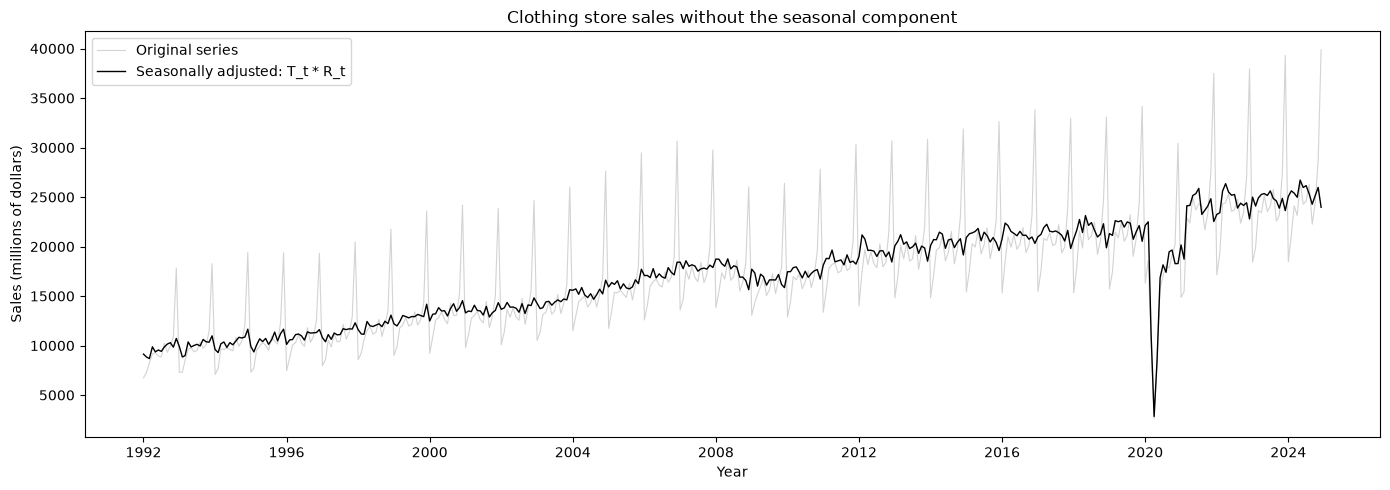

,sales,cma,seasonal_residual,seasonal,trend_residual
date,,,,,
1992-01-01,6734,NaN,NaN,0.737238,9134.089395
1992-02-01,7302,NaN,NaN,0.826155,8838.532696
1992-03-01,8245,NaN,NaN,0.949387,8684.548733
1992-04-01,9152,NaN,NaN,0.926950,9873.236706
1992-05-01,9294,NaN,NaN,0.992438,9364.818159
...,...,...,...,...,...
2024-08-01,26262,NaN,NaN,1.037126,25321.905399
2024-09-01,22259,NaN,NaN,0.917101,24271.041338
2024-10-01,24359,NaN,NaN,0.969194,25133.263388


In [13]:
# Multiplicative model: Y_t / S_t = T_t * R_t
# The seasonal component is defined for every month, so there is no NaN here
df_train = df_train.assign(trend_residual=df_train["sales"] / df_train["seasonal"])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["sales"], color="lightgrey", linewidth=0.8, label="Original series")
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.set_title("Clothing store sales without the seasonal component")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_train

## 1.4. Trend forecasting

### 1.4.1. Linear
We first try a linear trend, fitted by OLS on the seasonally adjusted series.


                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       9321.9422    174.034     53.564      0.000    8979.791    9664.094
x1            38.8315      0.760     51.110      0.000      37.338      40.325

T_t = 38.83 * t + 9321.94   (R² = 0.869)


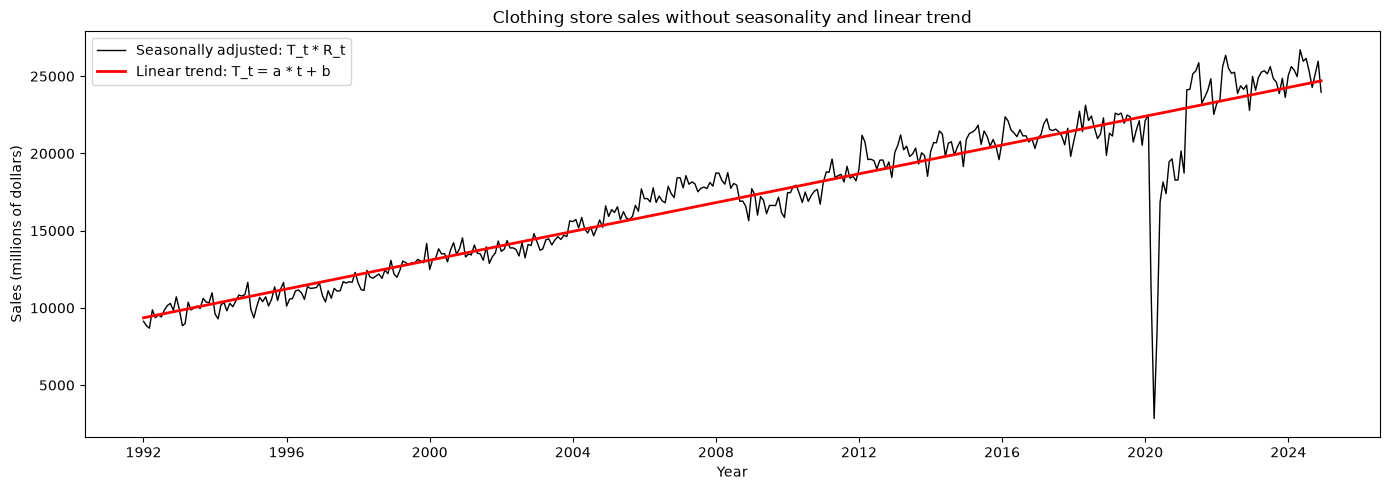

,sales,cma,seasonal_residual,seasonal,trend_residual,trend
date,,,,,,
1992-01-01,6734,NaN,NaN,0.737238,9134.089395,9360.773738
1992-02-01,7302,NaN,NaN,0.826155,8838.532696,9399.605271
1992-03-01,8245,NaN,NaN,0.949387,8684.548733,9438.436805
1992-04-01,9152,NaN,NaN,0.926950,9873.236706,9477.268338
1992-05-01,9294,NaN,NaN,0.992438,9364.818159,9516.099872
...,...,...,...,...,...,...
2024-08-01,26262,NaN,NaN,1.037126,25321.905399,24543.903338
2024-09-01,22259,NaN,NaN,0.917101,24271.041338,24582.734871
2024-10-01,24359,NaN,NaN,0.969194,25133.263388,24621.566405


In [14]:
import numpy as np

# Linear trend: T_t = a * t + b, fitted by OLS on the seasonally adjusted series (T_t * R_t)
# t is the time index (1, 2, ..., n), one step per month
t = np.arange(1, len(df_train) + 1)
X_trend = sm.add_constant(t)
linear_trend = sm.OLS(df_train["trend_residual"], X_trend).fit()
b_hat, a_hat_trend = linear_trend.params
print(linear_trend.summary().tables[1])
print(f"\nT_t = {a_hat_trend:.2f} * t + {b_hat:.2f}   (R² = {linear_trend.rsquared:.3f})")

# Trend component T_t
df_train = df_train.assign(trend=linear_trend.predict(X_trend))

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.plot(df_train.index, df_train["trend"], color="red", linewidth=2, label="Linear trend: T_t = a * t + b")
ax.set_title("Clothing store sales without seasonality and linear trend")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_train

> Linear trend

$R^2 = 0.869$: a straight line captures most of the growth, at about 38.8 million dollars more per month, every month (about 466 million per year). But the fit is not perfect: the series is below the line in 2009-2010 (crisis) and above it in 2022-2024, by about 750 to 960 million dollars per month. The COVID dip and rebound are also residuals that the line cannot absorb. The recent years being above the line is a warning for the forecast: the linear trend will probably **underestimate** the recent level.


### 1.4.2. Exponential Smoothing trend
We apply a double exponential smoothing (Brown's method, one parameter $0 < \lambda < 1$) on the seasonally adjusted series $Y'_t = T_t \cdot R_t$. The series is smoothed once, then the smoothed series is smoothed a second time.

**First smoothing:**

$$\hat{Y}_t = \lambda \, Y'_{t-1} + (1 - \lambda)\, \hat{Y}_{t-1}$$

**Second smoothing:**

$$\hat{\hat{Y}}_t = \lambda \, \hat{Y}_t + (1 - \lambda)\, \hat{\hat{Y}}_{t-1}$$

**Level and slope:**

$$b_t = 2\,\hat{Y}_t - \hat{\hat{Y}}_t \qquad a_t = \left(\hat{Y}_t - \hat{\hat{Y}}_t\right) \cdot \frac{\lambda}{1 - \lambda}$$

**Initialization:** $\hat{Y}_1 = \hat{\hat{Y}}_1 = Y'_1$

**Trend estimate on the train set:** $\hat{T}_t = b_t$

**Forecast** ($n$ = last train month, $h = 1, 2, \dots$):

$$\hat{T}_{n+h} = b_n + h \cdot a_n$$

**Choice of $\lambda$:** the fit error $\sum_t (Y'_t - b_t)^2$ keeps decreasing as $\lambda$ gets close to 1. With $\lambda \to 1$, $b_t$ copies the series and absorbs the residual $R_t$. We therefore fix $\lambda = 0.1$ to keep a smooth trend.


lambda = 0.1: last level b_n = 25688, last slope a_n = 59.3 per month


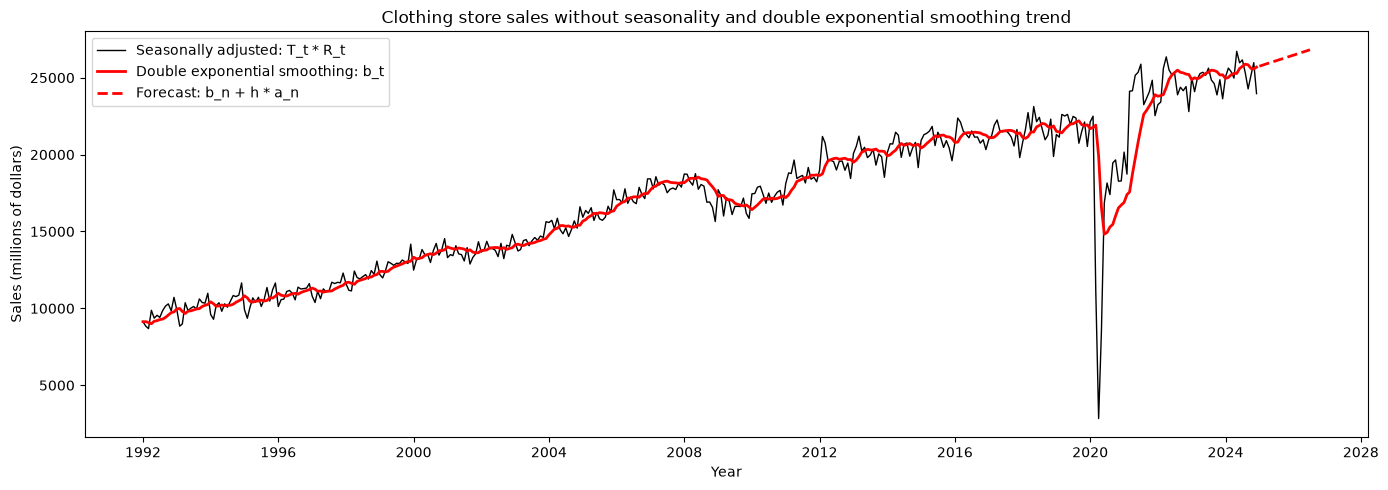

,sales,cma,seasonal_residual,seasonal,trend_residual,trend,trend_des
date,,,,,,,
1992-01-01,6734,NaN,NaN,0.737238,9134.089395,9360.773738,9134.089395
1992-02-01,7302,NaN,NaN,0.826155,8838.532696,9399.605271,9134.089395
1992-03-01,8245,NaN,NaN,0.949387,8684.548733,9438.436805,9077.933622
1992-04-01,9152,NaN,NaN,0.926950,9873.236706,9477.268338,9000.796484
1992-05-01,9294,NaN,NaN,0.992438,9364.818159,9516.099872,9161.003640
...,...,...,...,...,...,...,...
2024-08-01,26262,NaN,NaN,1.037126,25321.905399,24543.903338,25877.574126
2024-09-01,22259,NaN,NaN,0.917101,24271.041338,24582.734871,25839.990771
2024-10-01,24359,NaN,NaN,0.969194,25133.263388,24621.566405,25604.703229


In [15]:
def brown_double_smoothing(y, lam):
    """Brown's double exponential smoothing: returns the level b_t and the slope a_t."""
    s1 = np.empty(len(y))  # first smoothing: Y^_t
    s2 = np.empty(len(y))  # second smoothing: Y^^_t
    # Initialization: Y^_1 = Y^^_1 = Y'_1
    s1[0] = s2[0] = y[0]
    for t in range(1, len(y)):
        s1[t] = lam * y[t - 1] + (1 - lam) * s1[t - 1]
        s2[t] = lam * s1[t] + (1 - lam) * s2[t - 1]
    level = 2 * s1 - s2
    slope = (s1 - s2) * lam / (1 - lam)
    return level, slope


# Seasonally adjusted series Y'_t = T_t * R_t
y_adj = df_train["trend_residual"].to_numpy()

# The SSE keeps decreasing when lambda goes to 1 (b_t copies the series and absorbs R_t),
# so we fix a small lambda to keep a smooth trend
lambda_des = 0.1
level_des, slope_des = brown_double_smoothing(y_adj, lambda_des)

# Trend component T_t: the level b_t
df_train = df_train.assign(trend_des=level_des)

# Forecast over the test horizon: T_{n+h} = b_n + h * a_n
h = np.arange(1, len(df_test) + 1)
trend_des_forecast = pd.Series(level_des[-1] + h * slope_des[-1], index=df_test.index, name="trend_des")
print(f"lambda = {lambda_des}: last level b_n = {level_des[-1]:.0f}, last slope a_n = {slope_des[-1]:.1f} per month")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_train.index, df_train["trend_residual"], color="black", linewidth=1, label="Seasonally adjusted: T_t * R_t")
ax.plot(df_train.index, df_train["trend_des"], color="red", linewidth=2, label="Double exponential smoothing: b_t")
ax.plot(trend_des_forecast.index, trend_des_forecast, color="red", linestyle="--", linewidth=2, label="Forecast: b_n + h * a_n")
ax.set_title("Clothing store sales without seasonality and double exponential smoothing trend")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_train

> Exponential smoothing trend

This method uses the recent past to forecast the next values: the trend follows the series (it goes down in 2020, and up again in 2021), and is extended with the last slope. At the end of the train set, the level is $b_n = 25\,688$ (the linear trend gives 24 699) and the slope is 59 million dollars per month, against 38.8 for the linear trend. It is difficult to know which method is best at this stage, so we will compare both after recomposition, with the error measurements.


### 1.4.3. Detrend
We now have to detrend from our linear trend or from our double exponential smoothing (des). After that, we'll fit an ARIMA model to forecast both residual components (linear and des).


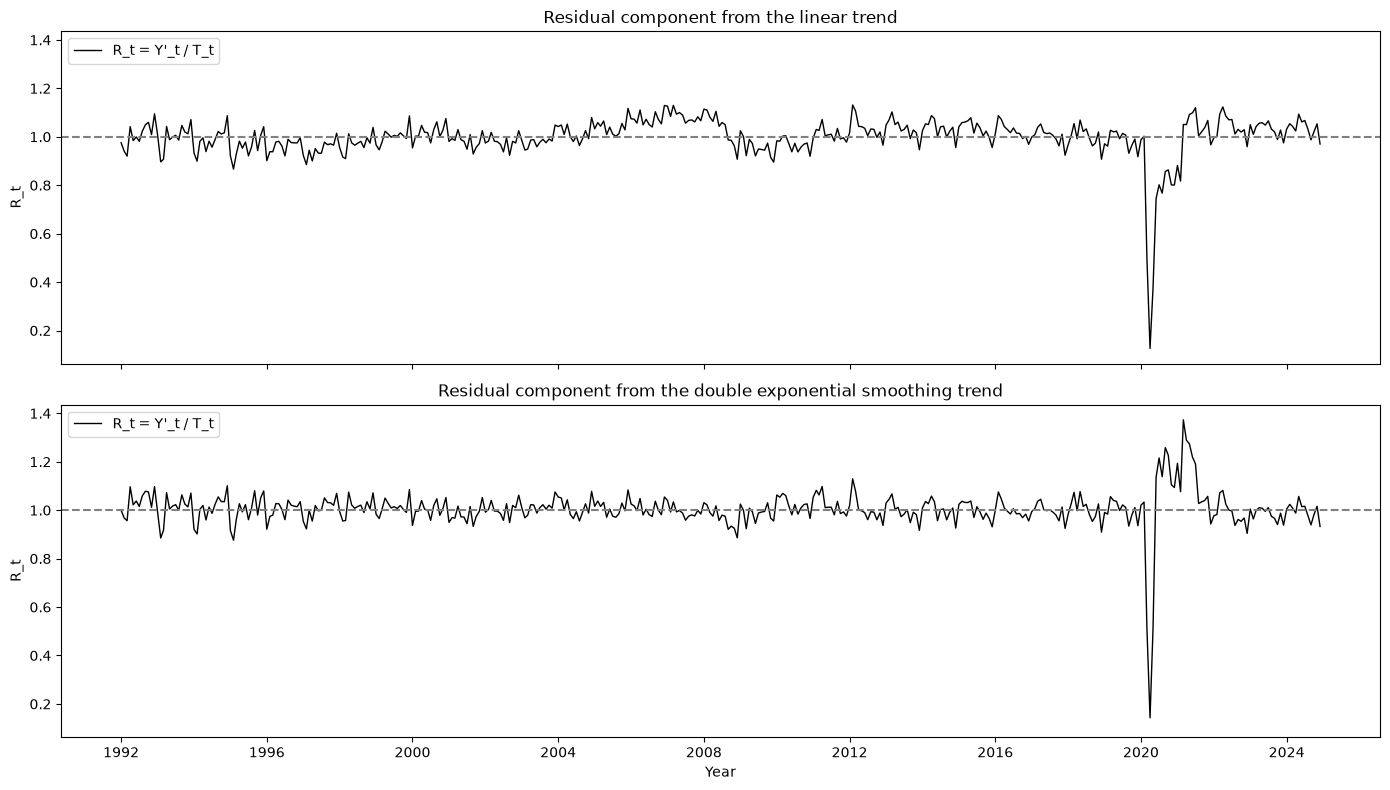

,sales,cma,seasonal_residual,seasonal,trend_residual,trend,trend_des,residual_linear,residual_des
date,,,,,,,,,
1992-01-01,6734,NaN,NaN,0.737238,9134.089395,9360.773738,9134.089395,0.975784,1.000000
1992-02-01,7302,NaN,NaN,0.826155,8838.532696,9399.605271,9134.089395,0.940309,0.967642
1992-03-01,8245,NaN,NaN,0.949387,8684.548733,9438.436805,9077.933622,0.920126,0.956666
1992-04-01,9152,NaN,NaN,0.926950,9873.236706,9477.268338,9000.796484,1.041781,1.096929
1992-05-01,9294,NaN,NaN,0.992438,9364.818159,9516.099872,9161.003640,0.984103,1.022248
...,...,...,...,...,...,...,...,...,...
2024-08-01,26262,NaN,NaN,1.037126,25321.905399,24543.903338,25877.574126,1.031698,0.978527
2024-09-01,22259,NaN,NaN,0.917101,24271.041338,24582.734871,25839.990771,0.987321,0.939282
2024-10-01,24359,NaN,NaN,0.969194,25133.263388,24621.566405,25604.703229,1.020782,0.981588


In [16]:
# Multiplicative model: Y'_t / T_t = (T_t * R_t) / T_t = R_t
# One residual component per trend estimate (linear and double exponential smoothing)
df_train = df_train.assign(
    residual_linear=df_train["trend_residual"] / df_train["trend"],
    residual_des=df_train["trend_residual"] / df_train["trend_des"],
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
residuals = [
    (axes[0], "residual_linear", "Residual component from the linear trend"),
    (axes[1], "residual_des", "Residual component from the double exponential smoothing trend"),
]
for ax, col, title in residuals:
    ax.plot(df_train.index, df_train[col], color="black", linewidth=1, label="R_t = Y'_t / T_t")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(title)
    ax.set_ylabel("R_t")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

df_train

> Residual components

Both residuals are centered around 1. The residual of the linear trend contains the slow deviations of the trend (2009 and the post-COVID level), so it is persistent. The residual of the DES trend is smaller and shorter-lived because the trend adapts, apart from the COVID shock (April 2020), which is the largest outlier of both series.


## 1.5. Residual Forecasting
In this section, the formulas written are **AI-generated** to ensure the implementation was as expected. You can find the prompt in the last section "AI-usage policy".


### 1.5.1. Stationarity
Before fitting an ARIMA model, the residual component $R_t$ must be stationary: constant mean, constant variance and no unit root. We check this for both residuals (`residual_linear` and `residual_des`) with two tools.

**Augmented Dickey-Fuller (ADF) test** (with a constant, number of lags $m$ chosen by AIC):

$$\Delta R_t = c + \gamma \, R_{t-1} + \sum_{i=1}^{m} \delta_i \, \Delta R_{t-i} + \varepsilon_t \qquad \text{with } \Delta R_t = R_t - R_{t-1}$$

- $H_0$: $\gamma = 0$, the series has a unit root (not stationary)
- $H_1$: $\gamma < 0$, the series is stationary

We reject $H_0$ at the 5% level if the p-value is below 0.05.

**Constant mean and variance:** like in section 1.1, we split the series into one window per year ($i = 1, \dots, 33$) and compute the mean $\bar{R}_i$ and the standard deviation $\text{Std}_i$ of each window. We then fit two OLS regressions on the year index:

$$\bar{R}_i = \alpha_1 + \beta_1 \, i + e_i \qquad \text{Std}_i = \alpha_2 + \beta_2 \, i + e_i$$

and run a t-test on $H_0$: $\beta = 0$ at 5%. If $H_0$ is not rejected, the mean (or the std) does not drift over time.

**Decision:** the series is stationary if the ADF test rejects $H_0$ **and** both t-tests do not reject $H_0$. Otherwise we difference it, $\Delta R_t = R_t - R_{t-1}$, and test again (up to $d = 2$).


residual_linear, d = 0: ADF = -3.894 (p-value = 0.0021, 13 lags) | slope of yearly mean: p-value = 0.780 | slope of yearly std: p-value = 0.195
-> residual_linear is stationary with d = 0

residual_des, d = 0: ADF = -6.059 (p-value = 0.0000, 14 lags) | slope of yearly mean: p-value = 0.926 | slope of yearly std: p-value = 0.178
-> residual_des is stationary with d = 0



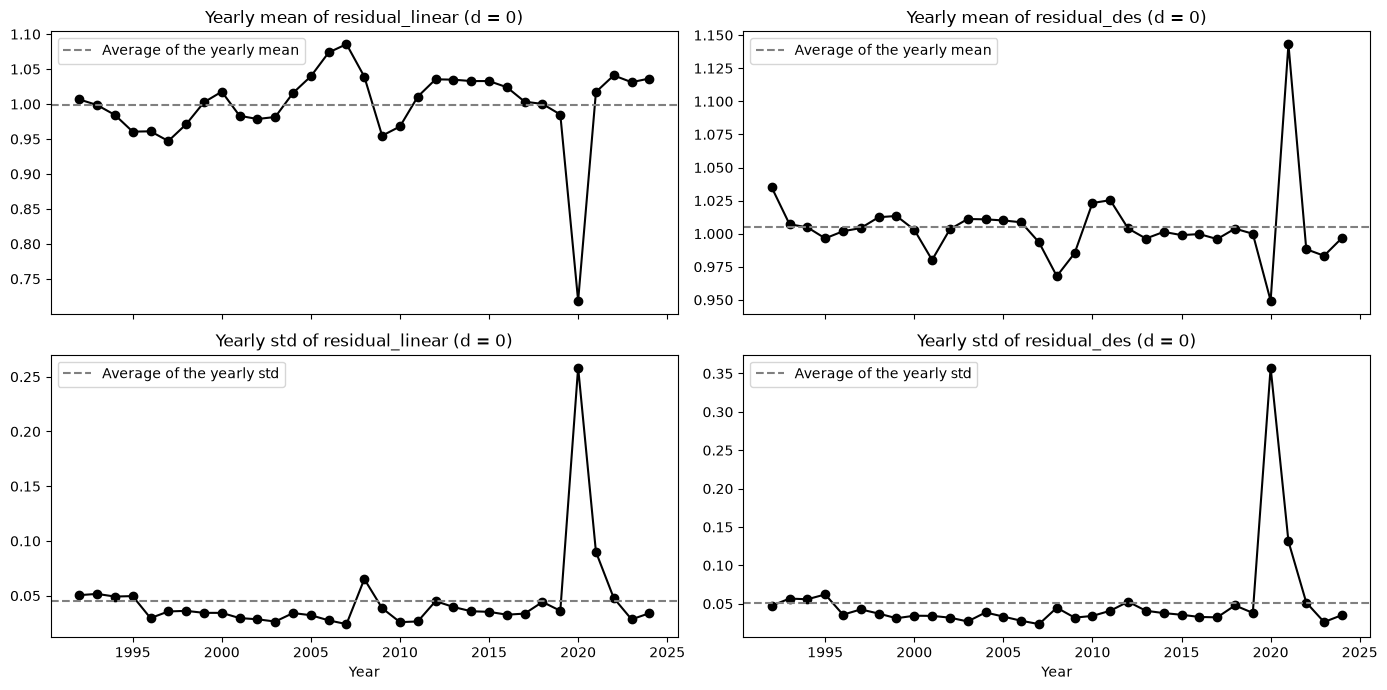

In [17]:
import warnings

from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore", category=FutureWarning)  # adfuller return-type notice


def stationarity_tests(series):
    """ADF test + t-tests on the slope of the yearly mean and yearly std."""
    adf_stat, adf_p, used_lag, *_ = adfuller(series, regression="c", autolag="AIC")
    # One window per calendar year, like in section 1.1
    yearly = series.groupby(series.index.year).agg(mean="mean", std="std")
    # Fit mean_i = alpha + beta * i and std_i = alpha + beta * i, then t-test on H0: beta = 0
    X_year = sm.add_constant(np.arange(len(yearly)))
    p_mean = sm.OLS(yearly["mean"], X_year).fit().pvalues.iloc[1]
    p_std = sm.OLS(yearly["std"], X_year).fit().pvalues.iloc[1]
    stationary = adf_p < alpha and p_mean >= alpha and p_std >= alpha
    return {"adf": adf_stat, "adf_p": adf_p, "used_lag": used_lag, "p_mean": p_mean, "p_std": p_std,
            "yearly": yearly, "stationary": stationary}


residual_cols = ["residual_linear", "residual_des"]
max_d = 2
# levels[col][k] is the series differenced k times; the last one is the stationary series
levels = {}
tests = {}
for col in residual_cols:
    levels[col] = [df_train[col]]
    for d in range(max_d + 1):
        result = stationarity_tests(levels[col][-1])
        print(
            f"{col}, d = {d}: ADF = {result['adf']:.3f} (p-value = {result['adf_p']:.4f}, {result['used_lag']} lags) | "
            f"slope of yearly mean: p-value = {result['p_mean']:.3f} | slope of yearly std: p-value = {result['p_std']:.3f}"
        )
        if result["stationary"] or d == max_d:
            break
        # Not stationary: difference once more, dR_t = R_t - R_{t-1}
        levels[col].append(levels[col][-1].diff().dropna())
    tests[col] = result
    verdict = "stationary" if result["stationary"] else "NOT stationary"
    print(f"-> {col} is {verdict} with d = {len(levels[col]) - 1}\n")

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for j, col in enumerate(residual_cols):
    yearly = tests[col]["yearly"]
    for i, stat in enumerate(["mean", "std"]):
        ax = axes[i, j]
        ax.plot(yearly.index, yearly[stat], marker="o", color="black")
        ax.axhline(yearly[stat].mean(), color="grey", linestyle="--", label=f"Average of the yearly {stat}")
        ax.set_title(f"Yearly {stat} of {col} (d = {len(levels[col]) - 1})")
        ax.legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("Year")
plt.tight_layout()
plt.show()

> Is $R_t$ stationary?

Both residuals are **stationary without differencing** ($d = 0$):

| Series | ADF (p-value) | Slope of the yearly mean (p-value) | Slope of the yearly std (p-value) |
|---|---|---|---|
| `residual_linear` | -3.89 (0.002) | 0.780 | 0.195 |
| `residual_des` | -6.06 (< 0.0001) | 0.926 | 0.178 |

The ADF test rejects the unit root at 5%, and neither the yearly mean nor the yearly std has a significant trend. On the plots, the only visible exception is 2020, when COVID produced a large drop and a large spread. This is a shock, not a drift, so the slope tests do not detect it.


### 1.5.2. PACF - Partial AutoCorrelation Function
The partial autocorrelation $\phi_{kk}$ at lag $k$ is the correlation between $R_t$ and $R_{t-k}$ once the effect of the intermediate lags $R_{t-1}, \dots, R_{t-k+1}$ has been removed. We compute it by OLS: $\phi_{kk}$ is the last coefficient of the AR($k$) regression

$$R_t = c + \phi_{k1} \, R_{t-1} + \phi_{k2} \, R_{t-2} + \dots + \phi_{kk} \, R_{t-k} + \varepsilon_t$$

**Significance:** under $H_0$: $\phi_{kk} = 0$, $\hat{\phi}_{kk}$ is approximately $\mathcal{N}(0, 1/n)$. Lag $k$ is significant at 5% if

$$|\hat{\phi}_{kk}| > \frac{1.96}{\sqrt{n}}$$

With $n = 396$ months, the band is about $\pm 0.099$. We look at the first 24 lags (two seasonal cycles).


residual_linear: band = +/-0.098, significant lags = [1, 3, 6, 8, 9, 13, 14]
  phi_kk of the first lags: [ 0.73  -0.06   0.139  0.056]
residual_des: band = +/-0.098, significant lags = [1, 2, 6, 7, 8, 9, 13, 21]
  phi_kk of the first lags: [ 0.583 -0.195  0.046 -0.01 ]


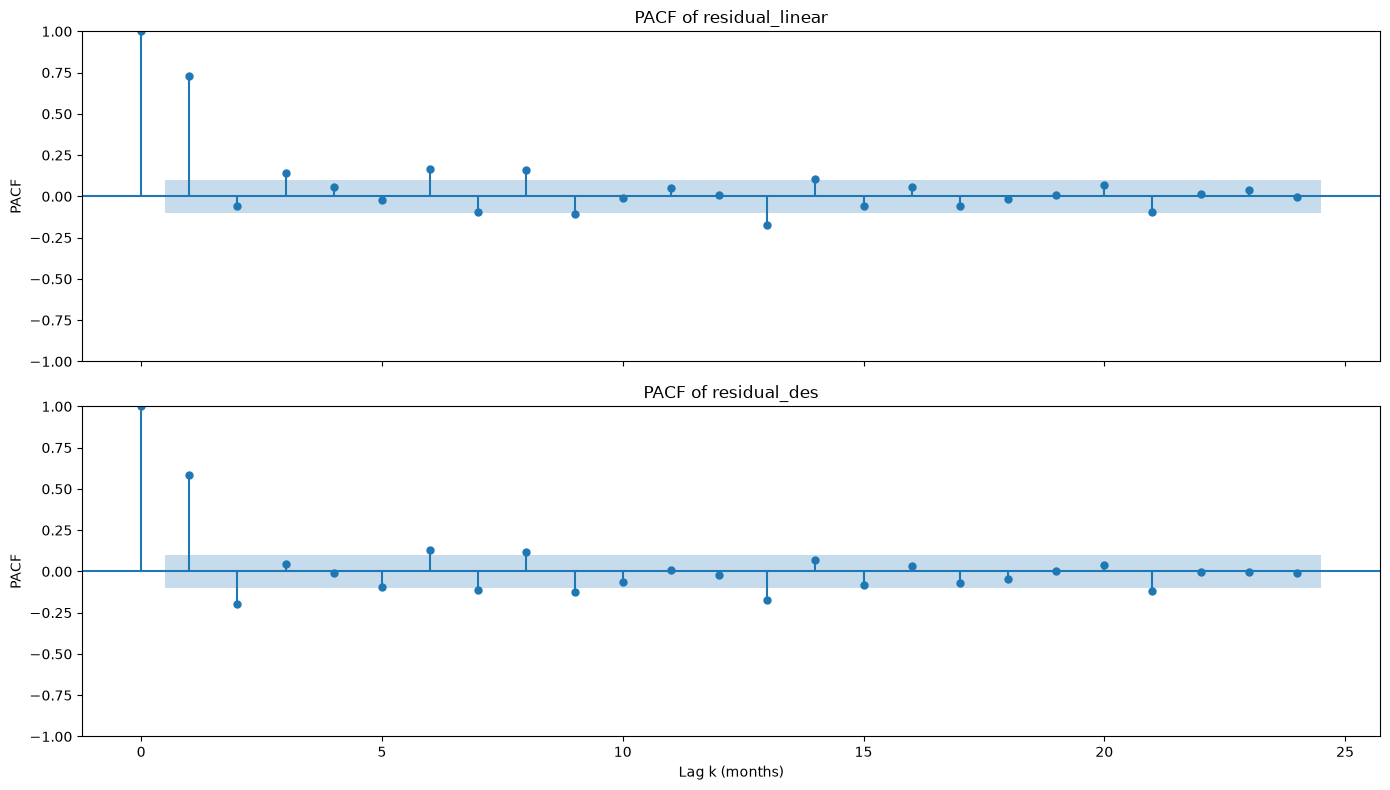

In [18]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import pacf

n_lags = 24  # two full seasonal cycles

significant_lags = {}
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, col in zip(axes, residual_cols):
    z = levels[col][-1]  # stationary series
    # PACF computed by OLS: phi_kk is the last coefficient of the AR(k) regression
    phi_kk = pacf(z, nlags=n_lags, method="ols")
    bound = 1.96 / np.sqrt(len(z))  # 95% confidence band under H0: phi_kk = 0
    significant_lags[col] = [k for k in range(1, n_lags + 1) if abs(phi_kk[k]) > bound]
    print(f"{col}: band = +/-{bound:.3f}, significant lags = {significant_lags[col]}")
    print(f"  phi_kk of the first lags: {np.round(phi_kk[1:5], 3)}")

    plot_pacf(z, lags=n_lags, method="ols", ax=ax, title=f"PACF of {col}")
    ax.set_ylabel("PACF")
axes[1].set_xlabel("Lag k (months)")
plt.tight_layout()
plt.show()

> Significant lags

| Series | Significant lags $k$ |
|---|---|
| `residual_linear` | 1, 3, 6, 8, 9, 13, 14 |
| `residual_des` | 1, 2, 6, 7, 8, 9, 13, 21 |

For both residuals, lag 1 is by far the strongest ($\hat{\phi}_{11} = 0.73$ for linear and $0.58$ for DES): a month above its trend is usually followed by another month above it, as the economy moves slowly. The first autocorrelation is weaker for DES because this trend already absorbs a part of the persistence. Lag 13 is also significant in both cases: the month of last year, corrected by the lag-1 effect, still has information, which hints at a seasonal pattern that the fixed coefficients did not capture.


### 1.5.3. ARIMA
When $d = 0$, the ARIMA($p$, $d$, 0) model reduces to an AR model on $R_t$, fitted only on a set of lags $K = \{k_1, \dots, k_p\}$:

$$R_t = c + \sum_{k \in K} \phi_k \, R_{t-k} + \varepsilon_t$$

**Estimation:** OLS regression of $R_t$ on its lagged values $R_{t-k}$, $k \in K$

**Ljung-Box test** on the regression residuals $\hat{\varepsilon}_t$, with $\hat{\rho}_j$ the autocorrelation of $\hat{\varepsilon}_t$ at lag $j$:

$$Q(h) = n(n+2) \sum_{j=1}^{h} \frac{\hat{\rho}_j^2}{n - j} \sim \chi^2(h - p) \text{ under } H_0$$

- $H_0$: no autocorrelation up to lag $h$, the residuals are white noise
- $H_1$: at least one $\rho_j \neq 0$

We use $h = 12$ and $h = 24$, and remove the $p$ estimated coefficients from the degrees of freedom. We reject $H_0$ at 5% if the p-value is below 0.05. The residuals are white noise if $H_0$ is not rejected at both $h$.

**Lag selection (Box-Jenkins iteration):**
1. Start with $K$ = the significant lags of the PACF (section 1.5.2), fit the model and run the Ljung-Box test.
2. If $H_0$ is rejected, some structure is left in $\hat{\varepsilon}_t$. The candidates are the lags $j \notin K$ where the residual ACF is significant: $|\hat{\rho}_j| > 1.96 / \sqrt{n}$.
3. Refit the model once with each candidate added to $K$, and keep the candidate that gives the smallest $Q(24)$, i.e. the one that removes the most autocorrelation.
4. Repeat from step 1 until $H_0$ is not rejected, until no candidate is left, or after 10 steps.

**Recursive forecast** over the test period ($n$ = last train month, $h = 1, \dots, 19$):

$$\hat{R}_{n+h} = \hat{c} + \sum_{k \in K} \hat{\phi}_k \, \tilde{R}_{n+h-k} \qquad \text{with } \tilde{R}_s = \begin{cases} R_s & \text{if } s \le n \text{ (observed)} \\ \hat{R}_s & \text{if } s > n \text{ (already forecast)} \end{cases}$$

The future errors $\varepsilon_{n+h}$ are replaced by their expected value, 0. This is the best guess only if $\varepsilon_t$ is white noise, which is why the Ljung-Box test should pass before forecasting.

If the series had been differenced, we would forecast $\Delta R_t$ and integrate back with $\hat{R}_{n+h} = \hat{R}_{n+h-1} + \widehat{\Delta R}_{n+h}$. The code does it automatically when $d > 0$.


===== residual_linear, step 1: lags [1, 3, 6, 8, 9, 13, 14] =====
R2 = 0.563
      lb_stat  lb_pvalue
12  25.253574   0.000124
24  38.673727   0.001984
H0 rejected: the residuals are NOT white noise
Significant residual ACF at lags [2, 12, 24], Q(24) after adding each: {2: np.float64(36.7), 12: np.float64(26.4), 24: np.float64(35.5)}
-> add lag 12 and refit

===== residual_linear, step 2: lags [1, 3, 6, 8, 9, 12, 13, 14] =====
R2 = 0.577
      lb_stat  lb_pvalue
12  18.263276   0.001096
24  26.410219   0.048523
H0 rejected: the residuals are NOT white noise
Significant residual ACF at lags [2], Q(24) after adding each: {2: np.float64(17.6)}
-> add lag 2 and refit

===== residual_linear, step 3: lags [1, 2, 3, 6, 8, 9, 12, 13, 14] =====
R2 = 0.591
      lb_stat  lb_pvalue
12   7.829317   0.049674
24  17.559866   0.286511
H0 rejected: the residuals are NOT white noise
No significant lag left in the residual ACF: we stop and keep this model

                 coef    std err          t    

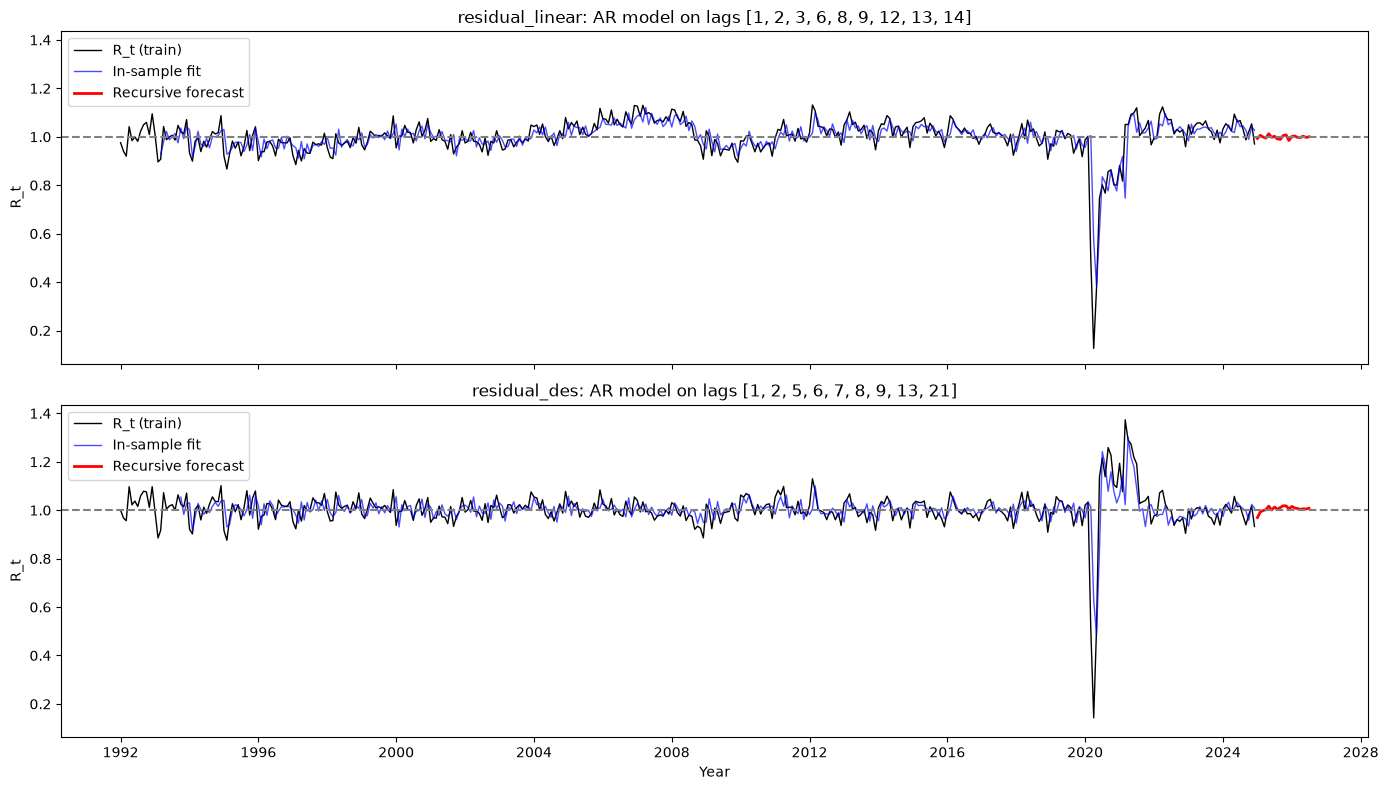

,residual_linear,residual_des
date,,
2025-01-01,0.993166,0.969472
2025-02-01,1.006022,0.993167
2025-03-01,0.999133,0.998153
2025-04-01,0.994829,1.002356
2025-05-01,1.012570,1.016909
2025-06-01,0.997786,1.000886
2025-07-01,1.002034,1.012929
2025-08-01,0.991253,1.003848
2025-09-01,0.989169,1.011402


In [19]:
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf


def fit_ar(z, lags):
    """OLS regression z_t = c + sum_k phi_k * z_{t-k} + e_t, on the given lags only."""
    X_lags = pd.concat({f"lag_{k}": z.shift(k) for k in lags}, axis=1)
    data = pd.concat([z.rename("z"), X_lags], axis=1).dropna()
    return sm.OLS(data["z"], sm.add_constant(data[X_lags.columns])).fit()


def ljung_box(resid, n_params):
    """Ljung-Box test at h = 12 and 24. Q follows a chi2(h - p) under H0, p = number of AR coefficients."""
    return acorr_ljungbox(resid, lags=[12, 24], model_df=n_params)


max_steps = 10  # safety net for the Box-Jenkins iteration
ar_models = {}
ar_lags = {}
residual_forecast = pd.DataFrame(index=df_test.index)
for col in residual_cols:
    z = levels[col][-1]
    # Step 1: start from the significant PACF lags
    lags = list(significant_lags[col])
    step = 1
    while True:
        ar = fit_ar(z, lags)
        lb = ljung_box(ar.resid, len(lags))
        white_noise = (lb["lb_pvalue"] >= alpha).all()
        print(f"===== {col}, step {step}: lags {lags} =====")
        print(f"R2 = {ar.rsquared:.3f}")
        print(lb)
        if white_noise:
            print("H0 not rejected: the residuals are white noise\n")
            break
        print("H0 rejected: the residuals are NOT white noise")
        if step == max_steps:
            print("Maximum number of steps reached: we stop and keep this model\n")
            break

        # Step 2: the candidates are the lags where the residual ACF is significant
        rho = acf(ar.resid, nlags=n_lags)
        bound = 1.96 / np.sqrt(len(ar.resid))
        candidates = [k for k in range(1, n_lags + 1) if abs(rho[k]) > bound and k not in lags]
        if not candidates:
            print("No significant lag left in the residual ACF: we stop and keep this model\n")
            break
        # Refit with each candidate and keep the one that removes the most autocorrelation (smallest Q(24))
        q24 = {k: ljung_box(fit_ar(z, sorted(lags + [k])).resid, len(lags) + 1)["lb_stat"].iloc[-1] for k in candidates}
        new_lag = min(q24, key=q24.get)
        print(f"Significant residual ACF at lags {candidates}, Q(24) after adding each: "
              f"{ {k: round(q, 1) for k, q in q24.items()} }")
        print(f"-> add lag {new_lag} and refit\n")
        lags = sorted(lags + [new_lag])
        step += 1
    ar_models[col] = ar
    ar_lags[col] = lags
    print(ar.summary().tables[1])

    # Recursive forecast: each prediction is fed back as a lagged value for the next months
    history = list(z.to_numpy())
    for _ in range(len(df_test)):
        history.append(ar.params["const"] + sum(ar.params[f"lag_{k}"] * history[-k] for k in lags))
    forecast = pd.Series(history[-len(df_test):], index=df_test.index)

    # If the series was differenced, integrate back: R_{n+h} = R_{n+h-1} + dR_{n+h}
    for level in reversed(levels[col][:-1]):
        forecast = level.iloc[-1] + forecast.cumsum()
    residual_forecast[col] = forecast

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, col in zip(axes, residual_cols):
    fitted = ar_models[col].fittedvalues
    ax.plot(df_train.index, df_train[col], color="black", linewidth=1, label="R_t (train)")
    if len(levels[col]) == 1:
        ax.plot(fitted.index, fitted, color="blue", linewidth=1, alpha=0.7, label="In-sample fit")
    ax.plot(residual_forecast.index, residual_forecast[col], color="red", linewidth=2, label="Recursive forecast")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(f"{col}: AR model on lags {ar_lags[col]}")
    ax.set_ylabel("R_t")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

residual_forecast

> ARIMA results

| Series | Step | Lags $K$ | $R^2$ | Ljung-Box $h = 12$ (p-value) | Ljung-Box $h = 24$ (p-value) | White noise? |
|---|---|---|---|---|---|---|
| `residual_linear` | 1 (PACF) | 1, 3, 6, 8, 9, 13, 14 | 0.563 | 0.0001 | 0.002 | No |
| `residual_linear` | 2 (+ lag 12) | 1, 3, 6, 8, 9, 12, 13, 14 | 0.577 | 0.001 | 0.049 | No |
| `residual_linear` | 3 (+ lag 2) | 1, 2, 3, 6, 8, 9, 12, 13, 14 | 0.591 | 0.050 | 0.287 | Borderline |
| `residual_des` | 1 (PACF) | 1, 2, 6, 7, 8, 9, 13, 21 | 0.412 | 0.003 | 0.046 | No |
| `residual_des` | 2 (+ lag 5) | 1, 2, 5, 6, 7, 8, 9, 13, 21 | 0.424 | 0.016 | 0.180 | No (at $h = 12$) |

With only the PACF lags, **the Ljung-Box test rejects white noise for both models**. The Box-Jenkins iteration adds the lags where the residual ACF is still significant (lag 12 and lag 2 for the linear residual, lag 5 for the DES residual) and improves the test a lot. In the end:
- the linear model is on the edge at $h = 12$ (p-value $= 0.0497$) and passes at $h = 24$;
- the DES model passes at $h = 24$ but not at $h = 12$ (p-value $= 0.016$), and the iteration stops because no significant lag remains in the residual ACF.

So **the residuals are not perfectly white noise**: a small autocorrelation remains that a sparse AR model cannot remove (the COVID outliers inflate the residual variance and hide the structure). The AR models can still be used to forecast, but the remaining autocorrelation is a limit of the method, which we keep in mind for the conclusion. Also note that the COVID months weigh on the estimation, and a dummy for these months would be a possible improvement.


## 1.6. Forecast and Recomposition
We now have a forecast for each component, so we can recompose the series with the multiplicative model $Y_t = T_t \cdot S_t \cdot R_t$. We do it twice, once with the linear trend and once with the double exponential smoothing (DES) trend.

**Trend forecast** ($n$ = last train month, $h = 1, \dots, 19$):
- Linear: $\hat{T}_{n+h} = \hat{a} \cdot (n + h) + \hat{b}$
- DES: $\hat{T}_{n+h} = b_n + h \cdot a_n$ (already computed in section 1.4.2)

**Seasonal forecast:** $\hat{S}_{n+h} = S_m$, the seasonal coefficient of the calendar month (section 1.3.2).

**Residual forecast:** $\hat{R}_{n+h}$, the recursive AR forecast of section 1.5.3 (one per trend).

**Recomposition:**
- On the train set (in-sample fit): $\hat{Y}_t = T_t \cdot S_t \cdot \hat{R}_t$, with $\hat{R}_t$ the fitted values of the AR model. The first $\max(K)$ months have no fitted value because their lags are missing.
- On the test set (forecast of January 2025 to July 2026): $\hat{Y}_{n+h} = \hat{T}_{n+h} \cdot \hat{S}_{n+h} \cdot \hat{R}_{n+h}$


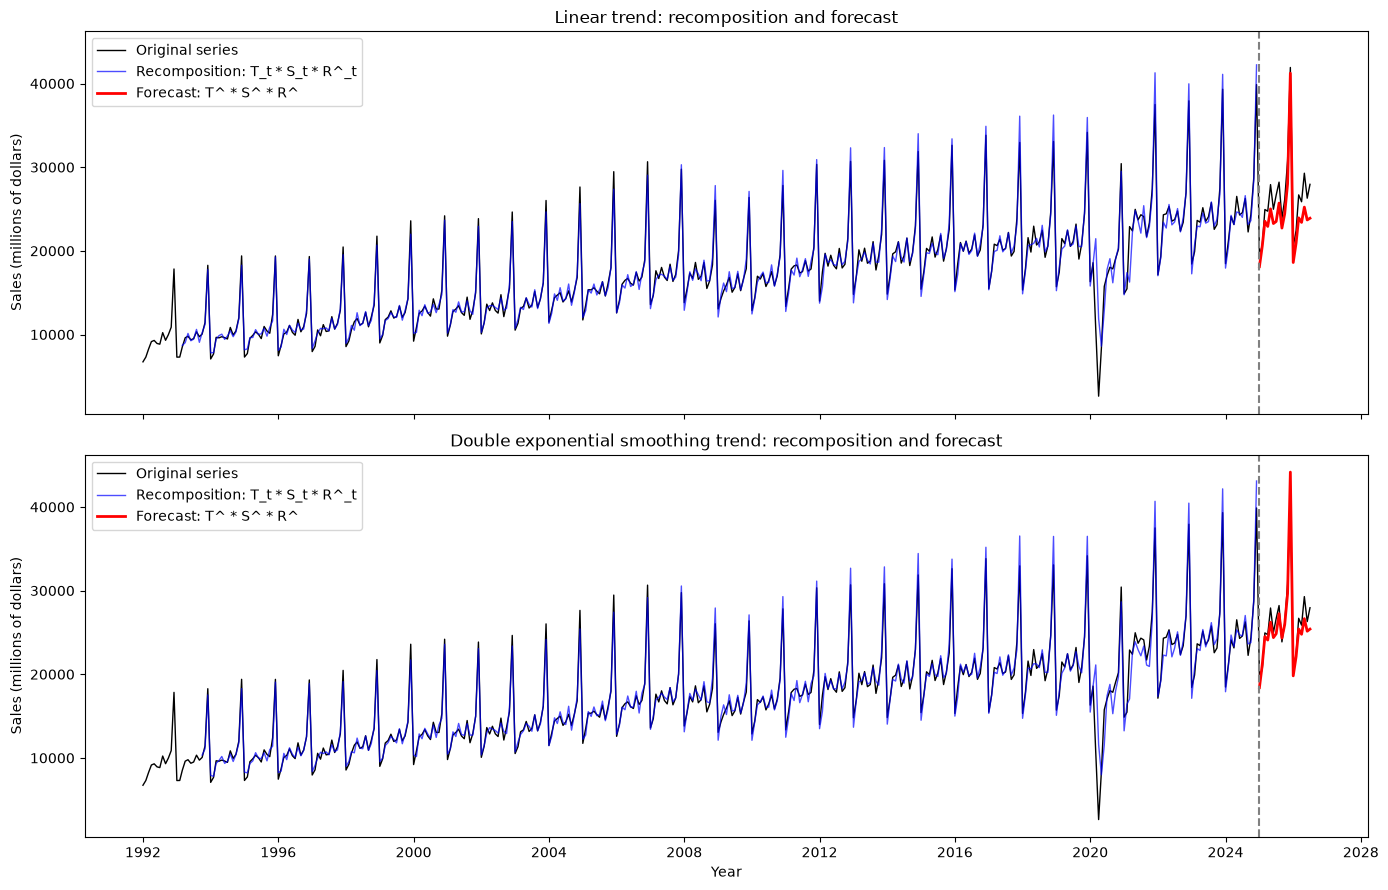

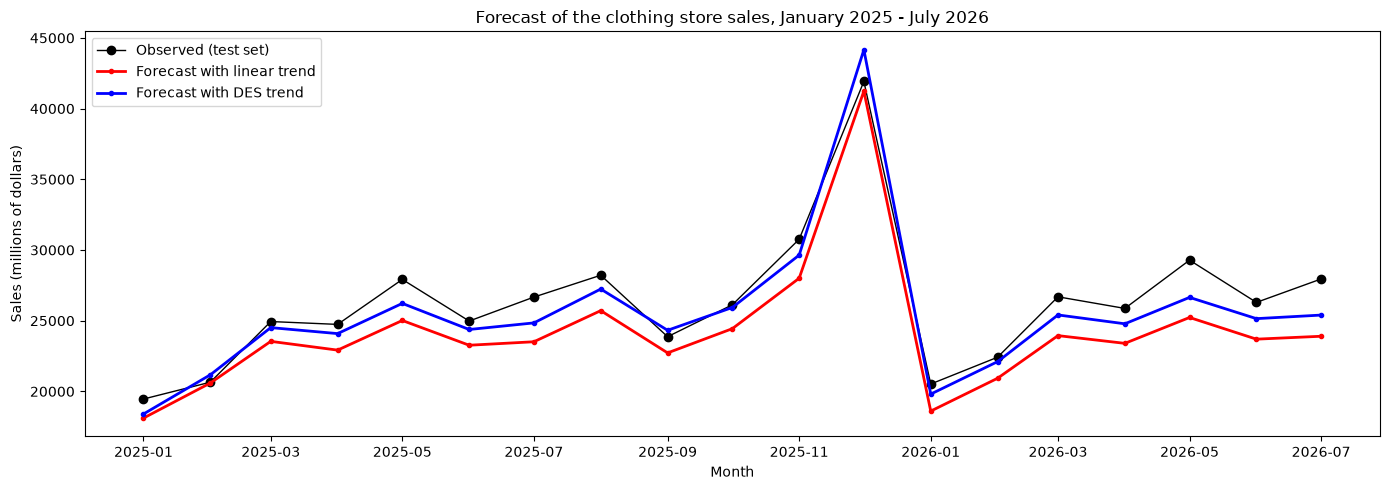

,sales,trend,trend_des,seasonal,residual_linear,residual_des,forecast_linear,forecast_des
date,,,,,,,,
2025-01-01,19461,24738.061005,25747.296206,0.737238,0.993166,0.969472,18113.215679,18402.411444
2025-02-01,20653,24776.892539,25806.611617,0.826155,1.006022,0.993167,20592.831977,21174.594580
2025-03-01,24941,24815.724072,25865.927029,0.949387,0.999133,0.998153,23539.301592,24511.437523
2025-04-01,24739,24854.555606,25925.242440,0.926950,0.994829,1.002356,22919.807923,24088.032362
2025-05-01,27920,24893.387139,25984.557851,0.992438,1.012570,1.016909,25015.679907,26224.110216


In [20]:
# Linear trend forecast: extend T_t = a * t + b over the test horizon (t = n+1, ..., n+h)
t_test = np.arange(len(df_train) + 1, len(df_train) + len(df_test) + 1)
trend_linear_forecast = pd.Series(linear_trend.predict(sm.add_constant(t_test)), index=df_test.index)

# Seasonal forecast: each future month gets the coefficient of its calendar month
seasonal_forecast = pd.Series(df_test.index.month.map(seasonal_coef).to_numpy(), index=df_test.index)

# In-sample recomposition on the train set: Y^_t = T_t * S_t * R^_t, with R^_t the AR fitted values
# (NaN for the first max(K) months, whose lags are missing)
df_train = df_train.assign(
    recomposed_linear=df_train["trend"] * df_train["seasonal"] * ar_models["residual_linear"].fittedvalues,
    recomposed_des=df_train["trend_des"] * df_train["seasonal"] * ar_models["residual_des"].fittedvalues,
)

# Forecast over the test period: Y^_{n+h} = T^_{n+h} * S^_{n+h} * R^_{n+h}
df_forecast = pd.DataFrame(
    {
        "sales": df_test["sales"],
        "trend": trend_linear_forecast,
        "trend_des": trend_des_forecast,
        "seasonal": seasonal_forecast,
        "residual_linear": residual_forecast["residual_linear"],
        "residual_des": residual_forecast["residual_des"],
    }
)
df_forecast = df_forecast.assign(
    forecast_linear=df_forecast["trend"] * df_forecast["seasonal"] * df_forecast["residual_linear"],
    forecast_des=df_forecast["trend_des"] * df_forecast["seasonal"] * df_forecast["residual_des"],
)

# Full period: recomposition on the train set and forecast on the test set
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, sharey=True)
methods = [
    (axes[0], "recomposed_linear", "forecast_linear", "Linear trend"),
    (axes[1], "recomposed_des", "forecast_des", "Double exponential smoothing trend"),
]
for ax, recomposed_col, forecast_col, name in methods:
    ax.plot(df.index, df["sales"], color="black", linewidth=1, label="Original series")
    ax.plot(df_train.index, df_train[recomposed_col], color="blue", linewidth=1, alpha=0.7, label="Recomposition: T_t * S_t * R^_t")
    ax.plot(df_forecast.index, df_forecast[forecast_col], color="red", linewidth=2, label="Forecast: T^ * S^ * R^")
    ax.axvline(df_test.index[0], color="grey", linestyle="--")
    ax.set_title(f"{name}: recomposition and forecast")
    ax.set_ylabel("Sales (millions of dollars)")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

# Zoom on the test period: both forecasts against the observed values
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_forecast.index, df_forecast["sales"], color="black", marker="o", linewidth=1, label="Observed (test set)")
ax.plot(df_forecast.index, df_forecast["forecast_linear"], color="red", marker=".", linewidth=2, label="Forecast with linear trend")
ax.plot(df_forecast.index, df_forecast["forecast_des"], color="blue", marker=".", linewidth=2, label="Forecast with DES trend")
ax.set_title("Forecast of the clothing store sales, January 2025 - July 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

df_forecast.head(5)

> Forecast and recomposition

On the train set, both recompositions follow the original series closely: the trend and the seasonality give the shape, and the AR model on $R_t$ corrects part of the deviations, including the COVID drop.

On the test set, both forecasts have the right seasonal shape, with the December 2025 peak well placed, but **both forecasts are below the observed values** for almost every month. The linear trend is clearly the lowest, since it was already below the end of the train set. The DES forecast, which follows the recent level and slope, is much closer to the observed values.

We will measure these errors precisely in the next section.


## 1.7. Errors measurement
We compare the forecast $\hat{Y}_t$ with the observed values $Y_t$ of the test set, for both trends. With $e_t = Y_t - \hat{Y}_t$ and $N$ the number of forecast months:

| Metric | Formula | Meaning |
|---|---|---|
| ME (Mean Error) | $\frac{1}{N} \sum_t e_t$ | Bias: $> 0$ if the forecast is too low on average, $< 0$ if too high |
| MAE (Mean Absolute Error) | $\frac{1}{N} \sum_t \lvert e_t \rvert$ | Average size of the error, in millions of dollars |
| MSE (Mean Squared Error) | $\frac{1}{N} \sum_t e_t^2$ | Squared error: large errors weigh a lot |
| RMSE (Root Mean Squared Error) | $\sqrt{\frac{1}{N} \sum_t e_t^2}$ | Like the MSE, but in the unit of the series |
| MAPE (Mean Absolute Percentage Error) | $\frac{100}{N} \sum_t \frac{\lvert e_t \rvert}{Y_t}$ | Average error in % of the observed value |
| sMAPE (symmetric MAPE) | $\frac{100}{N} \sum_t \frac{2 \lvert e_t \rvert}{\lvert Y_t \rvert + \lvert \hat{Y}_t \rvert}$ | Like the MAPE, but over- and under-forecasts are penalized the same way |

We compute them on the full test set (19 months), then on the complete year 2025 (12 months) and on 2026 (7 months) separately.


ME     MAE        MSE    RMSE  MAPE (%)  \
Period             Method                                                      
2025-01 -> 2026-07 Linear trend  2131.7  2131.7  5582238.2  2362.7       8.1   
                   DES trend      792.7  1131.5  1803299.5  1342.9       4.2   
2025               Linear trend  1764.9  1764.9  3911250.5  1977.7       6.7   
                   DES trend      444.1   980.6  1337960.8  1156.7       3.6   
2026-01 -> 2026-07 Linear trend  2760.6  2760.6  8446788.5  2906.3      10.6   
                   DES trend     1390.1  1390.1  2601022.8  1612.8       5.2   

                                 sMAPE (%)  
Period             Method                   
2025-01 -> 2026-07 Linear trend        8.5  
                   DES trend           4.3  
2025               Linear trend        7.0  
                   DES trend           3.6  
2026-01 -> 2026-07 Linear trend       11.2  
                   DES trend           5.4

date,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01
Linear trend,-6.9,-0.3,-5.6,-7.4,-10.4,-6.8,-11.8,-8.9,-4.8,-6.5,-9.0,-1.6,-9.3,-6.6,-10.3,-9.6,-13.8,-9.9,-14.5
DES trend,-5.4,2.5,-1.7,-2.6,-6.1,-2.4,-6.8,-3.5,1.9,-0.7,-3.6,5.4,-3.5,-1.4,-4.8,-4.2,-9.0,-4.4,-9.1


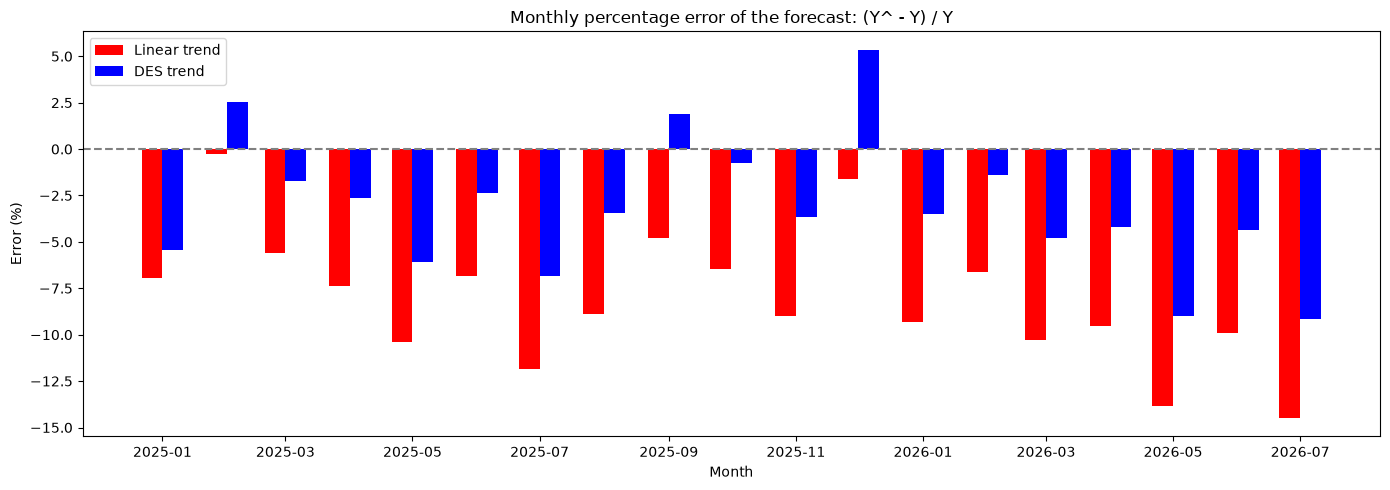

In [21]:
def error_metrics(y, y_hat):
    """ME, MAE, MSE, RMSE, MAPE and sMAPE between the observed values y and the forecast y_hat."""
    e = y - y_hat
    return {
        "ME": e.mean(),
        "MAE": e.abs().mean(),
        "MSE": (e**2).mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "MAPE (%)": 100 * (e.abs() / y).mean(),
        "sMAPE (%)": 100 * (2 * e.abs() / (y.abs() + y_hat.abs())).mean(),
    }


forecast_cols = {"Linear trend": "forecast_linear", "DES trend": "forecast_des"}
# Full test set, then the complete year 2025 and the half year 2026 separately
periods = {
    "2025-01 -> 2026-07": df_forecast,
    "2025": df_forecast.loc["2025"],
    "2026-01 -> 2026-07": df_forecast.loc["2026"],
}
errors = pd.DataFrame(
    {
        (period, method): error_metrics(data["sales"], data[col])
        for period, data in periods.items()
        for method, col in forecast_cols.items()
    }
).T
errors.index.names = ["Period", "Method"]
display(errors.round(1))

# Monthly percentage error (y_hat - y) / y, to see where the forecasts miss
monthly_errors = pd.DataFrame(
    {method: 100 * (df_forecast[col] - df_forecast["sales"]) / df_forecast["sales"] for method, col in forecast_cols.items()}
)
display(monthly_errors.round(1).T)

fig, ax = plt.subplots(figsize=(14, 5))
width = 10  # bar width, in days
for shift, (method, col), color in zip([-5, 5], forecast_cols.items(), ["red", "blue"]):
    pct_error = 100 * (df_forecast[col] - df_forecast["sales"]) / df_forecast["sales"]
    ax.bar(df_forecast.index + pd.Timedelta(days=shift), pct_error, width=width, color=color, label=method)
ax.axhline(0, color="grey", linestyle="--")
ax.set_title("Monthly percentage error of the forecast: (Y^ - Y) / Y")
ax.set_xlabel("Month")
ax.set_ylabel("Error (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> Errors measurement

Over the full test set, the **DES trend is much better than the linear trend** on every metric, with a MAPE of 4.2% against 8.1% (RMSE of 1 343 against 2 363 million dollars).

The ME is positive for both methods, and as large as the MAE for the linear trend (2 132): the linear forecast is **too low every month**, it is a pure bias and not noise. The monthly percentage errors confirm it: the linear trend underestimates by 5% to 14% almost every month, with the largest errors in 2026 (-14.5% in July 2026). The DES forecast is less biased (ME = 793) but the bias is still there, from about -9% in May and July 2026 to +5% in December 2025.

Both methods errors grow with the horizon (2026 is worse than 2025 for both). This is expected: the AR forecast of $R_t$ goes back to its mean quickly, and the trend is extrapolated at a fixed slope, while the real series kept growing faster than the historical trend (inflation and a post-COVID level change).


# 2. Facebook Prophet
Prophet is a forecasting library developed by Meta. Like the ETS decomposition, it splits the series into a trend, a seasonality and special events, but it estimates all of them at once in a single model, fitted by Bayesian optimization (Stan). With a multiplicative seasonality, the model is:

$$y(t) = g(t) \cdot \left(1 + s(t) + h(t)\right) + \varepsilon_t$$

- **Trend** $g(t)$: a piecewise linear growth. The slope can change at a set of **changepoints** (`n_changepoints` of them, placed in the first `changepoint_range` share of the train set). The size of the slope changes follows a Laplace prior whose scale is `changepoint_prior_scale`: a small value gives a rigid trend, a large value lets it follow the series closely (with a risk of overfitting).
- **Seasonality** $s(t)$: a Fourier series of order `yearly_fourier_order`, with a prior of scale `seasonality_prior_scale`. In the multiplicative mode, the seasonal effect is a percentage of the trend, which fits a series whose seasonal amplitude grows with the level.
- **Events** $h(t)$: an extra effect on chosen dates ("holidays"). We use it for the COVID months, so this shock is not absorbed by the trend or the seasonality.

**Forecast:** $g$, $s$ and $h$ are extended over the test period, 2025-01 to 2026-07. The trend keeps the last slope, and the uncertainty interval comes from simulated future changepoints.


## 2.1. Forecasting
All the parameters are defined in the next cell, so they are easy to change. The values are the Prophet defaults, except:
- `SEASONALITY_MODE = "multiplicative"`, because section 1.1 showed how the seasonal amplitude behaves with the level;
- no weekly or daily seasonality, because the data is monthly;
- `USE_COVID = True`, to model the COVID months (March 2020 to February 2021) as an event.

The model is fitted on the train set only (1992-2024), like in section 1.


In [22]:
# Prophet parameters:
SEASONALITY_MODE = "multiplicative"  # "multiplicative" or "additive"
GROWTH = "linear"  # "linear" or "flat"
YEARLY_FOURIER_ORDER = 10  # number of Fourier terms of the yearly seasonality (more = more flexible shape)
N_CHANGEPOINTS = 25  # number of potential trend changepoints
CHANGEPOINT_RANGE = 0.8  # share of the train set where changepoints can be placed
CHANGEPOINT_PRIOR_SCALE = 0.05  # trend flexibility (higher = the trend follows the series more closely)
SEASONALITY_PRIOR_SCALE = 10.0  # seasonality flexibility (higher = larger seasonal effects allowed)
USE_COVID = True  # model the COVID months as a special event, so they do not distort the trend
COVID_START, COVID_END = "2020-03-01", "2021-02-01"  # months treated as the COVID event
INTERVAL_WIDTH = 0.95  # width of the uncertainty interval

Importing plotly failed. Interactive plots will not work.


C:\Users\adrie\Documents\Adrien\Montpellier\5A\TSA\Luka\TSA_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


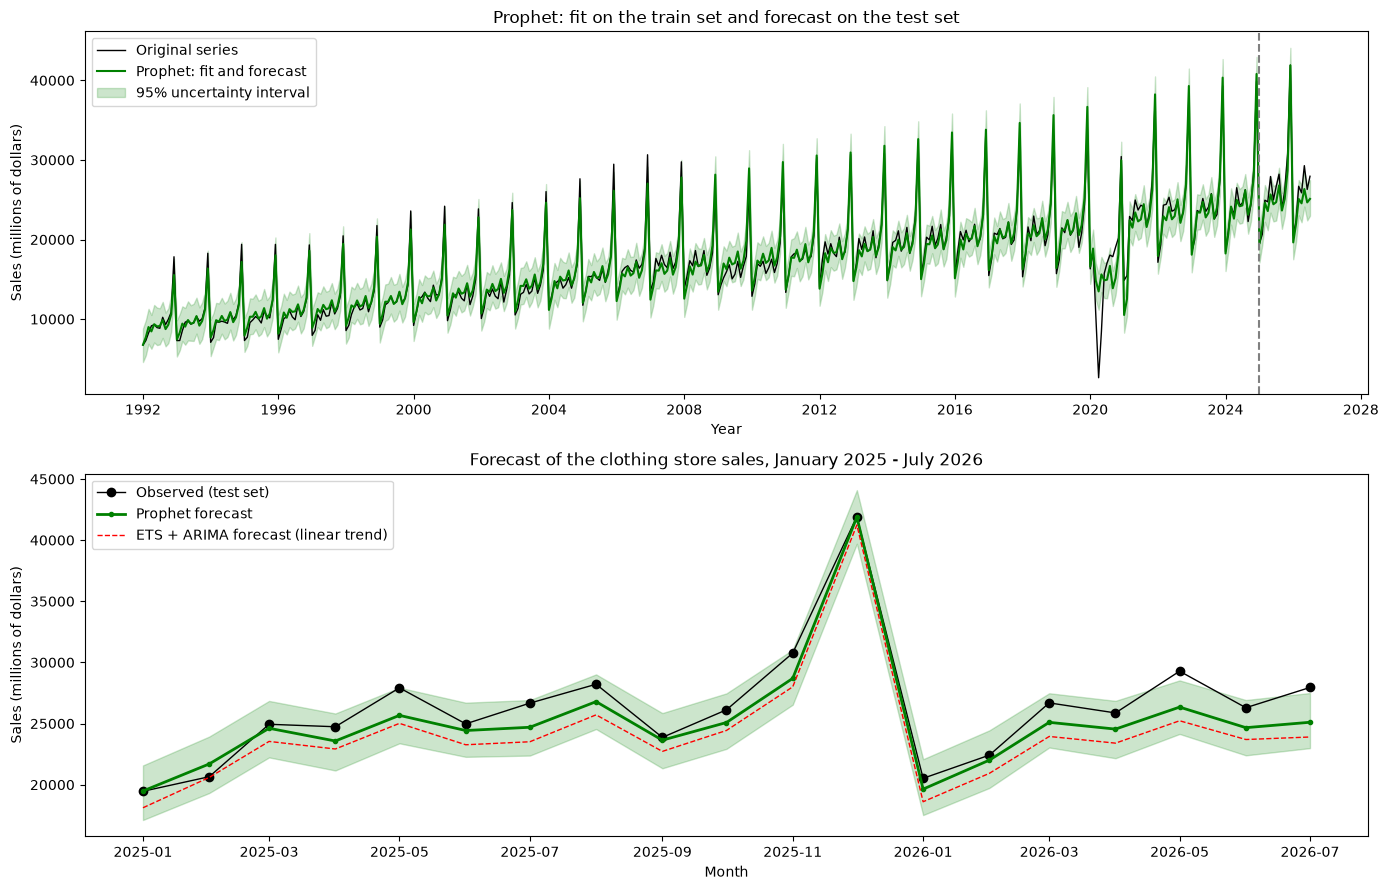

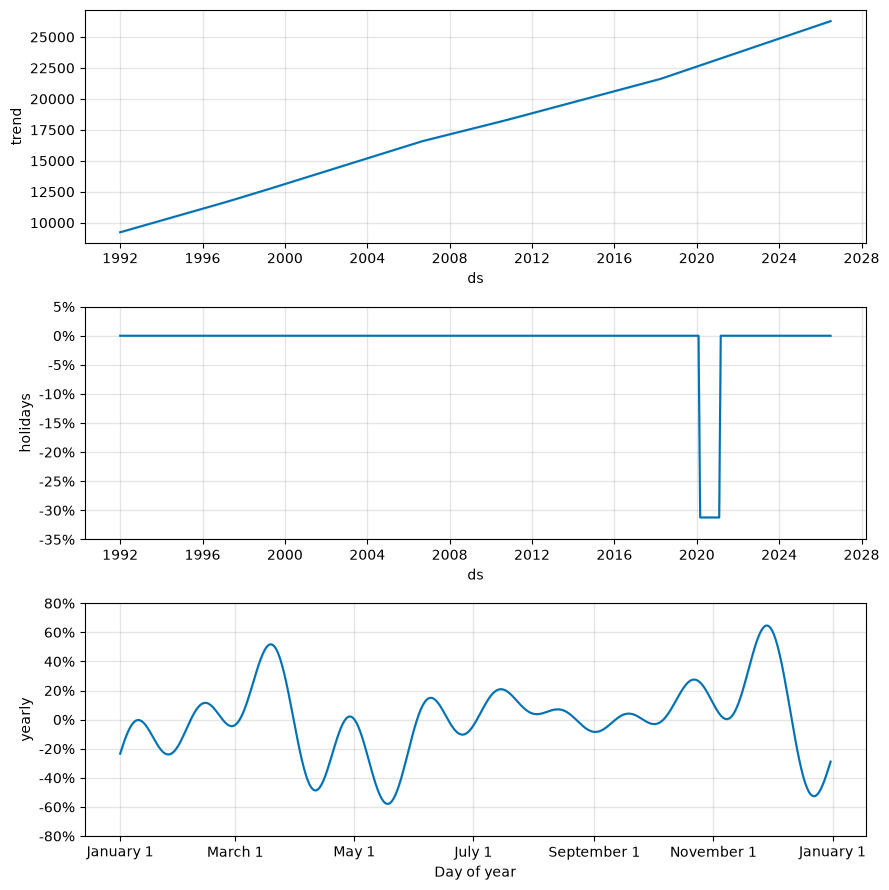

Observed values inside the 95% interval: 17 / 19


,sales,forecast_prophet,lower,upper
date,,,,
2025-01-01,19461,19484.618445,17113.041937,21575.359006
2025-02-01,20653,21696.291999,19318.063936,23936.482244
2025-03-01,24941,24615.115241,22231.281063,26849.967316
2025-04-01,24739,23573.254565,21161.254658,25822.242372
2025-05-01,27920,25669.837698,23383.857180,27935.425677
2025-06-01,24976,24430.657579,22276.737315,26707.623310
2025-07-01,26670,24696.635670,22381.352659,26920.696622
2025-08-01,28215,26791.960722,24550.149959,29020.280567
2025-09-01,23868,23640.996869,21340.933921,25857.137156


In [23]:
import logging
import warnings

from prophet import Prophet

# Hide the optimizer logs of cmdstanpy
logging.getLogger("cmdstanpy").disabled = True


def fit_prophet(train, horizon, **overrides):
    """Fit Prophet on `train` (column sales) and predict `train` + `horizon` months.

    The parameters of the cell above are used, except the ones given in `overrides`.
    """
    params = dict(
        growth=GROWTH,
        seasonality_mode=SEASONALITY_MODE,
        yearly_seasonality=YEARLY_FOURIER_ORDER,
        weekly_seasonality=False,
        daily_seasonality=False,
        n_changepoints=N_CHANGEPOINTS,
        changepoint_range=CHANGEPOINT_RANGE,
        changepoint_prior_scale=CHANGEPOINT_PRIOR_SCALE,
        seasonality_prior_scale=SEASONALITY_PRIOR_SCALE,
        interval_width=INTERVAL_WIDTH,
    )
    use_covid = overrides.pop("use_covid", USE_COVID)
    params.update(overrides)
    # COVID event: one "holiday" per month, all sharing the same effect
    if use_covid:
        params["holidays"] = pd.DataFrame(
            {"holiday": "covid", "ds": pd.date_range(COVID_START, COVID_END, freq="MS"), "lower_window": 0, "upper_window": 0}
        )
    model = Prophet(**params)
    # Prophet expects two columns: ds (date) and y (value)
    model.fit(train["sales"].reset_index().rename(columns={"date": "ds", "sales": "y"}))
    # Forecast the train months (in-sample fit) and the next months, one step per month
    future = model.make_future_dataframe(periods=horizon, freq="MS")
    return model, model.predict(future).set_index("ds")


prophet_model, prophet_pred = fit_prophet(df_train, len(df_test))

# Keep the test period next to the observed values
prophet_forecast = pd.DataFrame(
    {
        "sales": df_test["sales"],
        "forecast_prophet": prophet_pred.loc[df_test.index, "yhat"],
        "lower": prophet_pred.loc[df_test.index, "yhat_lower"],
        "upper": prophet_pred.loc[df_test.index, "yhat_upper"],
    }
)

# Full period: in-sample fit, forecast and uncertainty interval
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
ax = axes[0]
ax.plot(df.index, df["sales"], color="black", linewidth=1, label="Original series")
ax.plot(prophet_pred.index, prophet_pred["yhat"], color="green", linewidth=1.5, label="Prophet: fit and forecast")
ax.fill_between(prophet_pred.index, prophet_pred["yhat_lower"], prophet_pred["yhat_upper"], color="green", alpha=0.2,
                label=f"{INTERVAL_WIDTH:.0%} uncertainty interval")
ax.axvline(df_test.index[0], color="grey", linestyle="--")
ax.set_title("Prophet: fit on the train set and forecast on the test set")
ax.set_xlabel("Year")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")

# Zoom on the test period, with the ETS + ARIMA forecast (linear trend) of section 1.6 for comparison
ax = axes[1]
ax.plot(prophet_forecast.index, prophet_forecast["sales"], color="black", marker="o", linewidth=1, label="Observed (test set)")
ax.plot(prophet_forecast.index, prophet_forecast["forecast_prophet"], color="green", marker=".", linewidth=2, label="Prophet forecast")
ax.fill_between(prophet_forecast.index, prophet_forecast["lower"], prophet_forecast["upper"], color="green", alpha=0.2)
ax.plot(df_forecast.index, df_forecast["forecast_linear"], color="red", linestyle="--", linewidth=1, label="ETS + ARIMA forecast (linear trend)")
ax.set_title("Forecast of the clothing store sales, January 2025 - July 2026")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (millions of dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# Components found by Prophet: trend, yearly seasonality and COVID effect
prophet_model.plot_components(prophet_pred.reset_index())
plt.show()

inside = prophet_forecast["sales"].between(prophet_forecast["lower"], prophet_forecast["upper"])
print(f"Observed values inside the {INTERVAL_WIDTH:.0%} interval: {inside.sum()} / {len(inside)}")

prophet_forecast

> Prophet forecast

On the train set, Prophet follows the series well, including the COVID drop thanks to the COVID event. The components plot gives the three parts found by Prophet: a piecewise linear trend, a yearly seasonality (multiplicative, in % of the trend) and the COVID effect.

On the test set, the Prophet forecast has the right seasonal shape and the right order of magnitude. Like ETS + ARIMA, it is **below the observed values** for most months, especially in spring and summer 2026, because its trend does not fully catch the faster growth of 2025-2026. 17 of the 19 observed values stay inside the 95% uncertainty interval.


## 2.2. Errors measurements
We use the same metrics (ME, MAE, MSE, RMSE, MAPE, sMAPE) and the same periods as in section 1.7, so that we can compare Prophet with the ETS + ARIMA forecasts.


ME     MAE        MSE    RMSE  MAPE (%)  \
Period             Method                                                      
2025-01 -> 2026-07 Linear trend  2131.7  2131.7  5582238.2  2362.7       8.1   
                   DES trend      792.7  1131.5  1803299.5  1342.9       4.2   
                   Prophet       1137.0  1249.3  2307791.1  1519.1       4.7   
2025               Linear trend  1764.9  1764.9  3911250.5  1977.7       6.7   
                   DES trend      444.1   980.6  1337960.8  1156.7       3.6   
                   Prophet        832.0  1009.8  1603247.5  1266.2       3.8   
2026-01 -> 2026-07 Linear trend  2760.6  2760.6  8446788.5  2906.3      10.6   
                   DES trend     1390.1  1390.1  2601022.8  1612.8       5.2   
                   Prophet       1659.9  1659.9  3515580.2  1875.0       6.2   

                                 sMAPE (%)  
Period             Method                   
2025-01 -> 2026-07 Linear trend        8.5  
                   DES trend           4.3  
                   Prophet             4.8  
2025               Linear trend        7.0  
                   DES trend           3.6  
                   Prophet             3.9  
2026-01 -> 2026-07 Linear trend       11.2  
                   DES trend           5.4  
                   Prophet             6.5

date,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01
Prophet error (%),0.1,5.1,-1.3,-4.7,-8.1,-2.2,-7.4,-5.0,-1.0,-4.0,-6.7,-0.1,-4.3,-1.8,-6.0,-5.1,-10.0,-6.2,-10.2


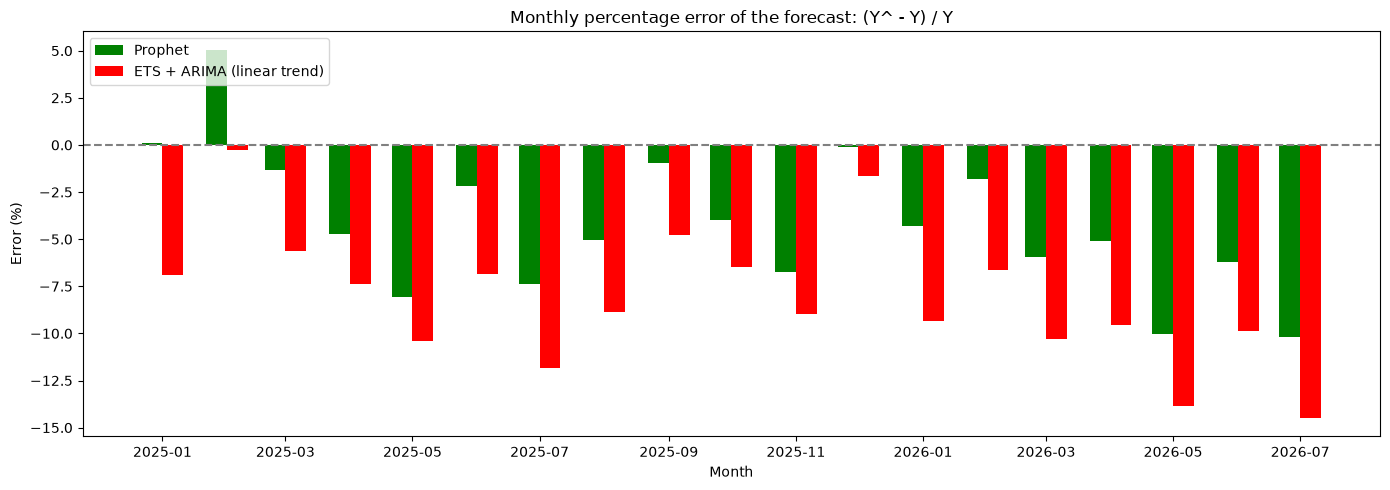

In [24]:
# Same metrics and periods as in section 1.7 (function error_metrics)
prophet_periods = {
    "2025-01 -> 2026-07": prophet_forecast,
    "2025": prophet_forecast.loc["2025"],
    "2026-01 -> 2026-07": prophet_forecast.loc["2026"],
}
prophet_errors = pd.DataFrame(
    {(period, "Prophet"): error_metrics(data["sales"], data["forecast_prophet"]) for period, data in prophet_periods.items()}
).T
prophet_errors.index.names = ["Period", "Method"]

# Comparison with the ETS + ARIMA forecasts of section 1.7
all_errors = pd.concat([errors, prophet_errors]).sort_index(level="Period", sort_remaining=False)
all_errors = all_errors.loc[list(prophet_periods)]
display(all_errors.round(1))

# Monthly percentage error (y_hat - y) / y of Prophet and of the ETS + ARIMA forecast (linear trend)
display((100 * (prophet_forecast["forecast_prophet"] - df_test["sales"]) / df_test["sales"]).round(1).to_frame("Prophet error (%)").T)

fig, ax = plt.subplots(figsize=(14, 5))
series = [
    ("Prophet", prophet_forecast["forecast_prophet"], "green"),
    ("ETS + ARIMA (linear trend)", df_forecast["forecast_linear"], "red"),
]
for shift, (name, y_hat, color) in zip([-5, 5], series):
    pct_error = 100 * (y_hat - df_test["sales"]) / df_test["sales"]
    ax.bar(df_test.index + pd.Timedelta(days=shift), pct_error, width=10, color=color, label=name)
ax.axhline(0, color="grey", linestyle="--")
ax.set_title("Monthly percentage error of the forecast: (Y^ - Y) / Y")
ax.set_xlabel("Month")
ax.set_ylabel("Error (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

> Errors measurement

With its default parameters, **Prophet is close to the ETS + ARIMA approach with the DES trend** and clearly better than the one with the linear trend:

| Method | MAPE (%) | RMSE | ME |
|---|---|---|---|
| ETS + ARIMA, linear trend | 8.1 | 2 363 | 2 132 |
| ETS + ARIMA, DES trend | 4.2 | 1 343 | 793 |
| Prophet (default) | 4.7 | 1 519 | 1 137 |

The DES trend is slightly better than Prophet on all the metrics, and Prophet is much more accurate than the linear trend. Both are biased in the same direction (forecast too low), but Prophet's errors are more regular: it follows the seasonal shape (monthly errors between +5% and -10%), whereas the linear trend loses 5% to 14% every month. On the first months of 2026, Prophet is worse than DES (MAPE of 6.2% against 5.2%).

The methods make similar errors because they share the same limit: they extrapolate the past trend, and the recent growth was faster.


## 2.3. Playing with the parameters
We change one parameter at a time and measure the MAPE on the test set. **Warning:** this is only meant to understand the effect of each parameter. Choosing a value because it is the best on the test set would not be fair, since the test set must stay unseen. The proper tuning is done just after, on a validation period taken inside the train set.


In [25]:
def test_mape(**overrides):
    """MAPE of a Prophet variant on the test set (for interpretation only, see the warning above)."""
    _, pred = fit_prophet(df_train, len(df_test), **overrides)
    return error_metrics(df_test["sales"], pred.loc[df_test.index, "yhat"])["MAPE (%)"]


experiments = {
    "Default parameters": {},
    "USE_COVID = False": {"use_covid": False},
    "SEASONALITY_MODE = additive": {"seasonality_mode": "additive"},
    "CHANGEPOINT_PRIOR_SCALE = 0.01": {"changepoint_prior_scale": 0.01},
    "CHANGEPOINT_PRIOR_SCALE = 0.5": {"changepoint_prior_scale": 0.5},
    "CHANGEPOINT_RANGE = 0.95": {"changepoint_range": 0.95},
    "YEARLY_FOURIER_ORDER = 5": {"yearly_seasonality": 5},
    "N_CHANGEPOINTS = 50": {"n_changepoints": 50},
}
experiment_results = pd.Series({name: test_mape(**kw) for name, kw in experiments.items()}, name="Test MAPE (%)")
display(experiment_results.round(2).to_frame())

,Test MAPE (%)
Default parameters,4.70
USE_COVID = False,8.02
SEASONALITY_MODE = additive,5.72
CHANGEPOINT_PRIOR_SCALE = 0.01,5.91
CHANGEPOINT_PRIOR_SCALE = 0.5,3.86
CHANGEPOINT_RANGE = 0.95,4.56
YEARLY_FOURIER_ORDER = 5,5.85
N_CHANGEPOINTS = 50,4.77


> Playing with the parameters

MAPE on the full test set, one parameter changed at a time:

| Change | MAPE (%) | Reading |
|---|---|---|
| Default parameters | 4.70 | reference |
| `USE_COVID = False` | 8.02 | the 2020 drop pulls the trend and the seasonality down |
| `SEASONALITY_MODE = additive` | 5.72 | the seasonal swings grow with the level, so the additive mode is less adapted |
| `CHANGEPOINT_PRIOR_SCALE = 0.01` | 5.91 | too rigid trend: it cannot follow the post-COVID level |
| `CHANGEPOINT_PRIOR_SCALE = 0.5` | 3.86 | a flexible trend follows the recent growth |
| `CHANGEPOINT_RANGE = 0.95` | 4.56 | changepoints allowed until the end of the train set: small gain |
| `YEARLY_FOURIER_ORDER = 5` | 5.85 | the seasonal shape (sharp December peak) needs enough Fourier terms |
| `N_CHANGEPOINTS = 50` | 4.77 | no effect, the prior scale controls the flexibility, not the number of candidates |

- Modeling COVID as an event is the most important choice: without it, the error almost doubles.
- The multiplicative mode confirms the choice of section 1.1.
- The trend flexibility (`CHANGEPOINT_PRIOR_SCALE`) matters most for the forecast, because the test period follows a period of fast growth.

The best value on the test set (0.5) was found by looking at the test set, so the comparison would not be fair. The next cell tunes this parameter on a validation period inside the train set.


In [26]:
# Fair tuning of the changepoint prior scale: fit on 1992-2022 and validate on 2023-2024, inside the train set
df_fit = df_train.loc[:"2022-12-01"]
df_val = df_train.loc["2023-01-01":]

val_mape = {}
for scale in [0.01, 0.05, 0.1, 0.3, 0.5]:
    _, pred = fit_prophet(df_fit, len(df_val), changepoint_prior_scale=scale)
    val_mape[scale] = error_metrics(df_val["sales"], pred.loc[df_val.index, "yhat"])["MAPE (%)"]
val_mape = pd.Series(val_mape, name="Validation MAPE (%)")
val_mape.index.name = "changepoint_prior_scale"
display(val_mape.round(2).to_frame())

best_scale = val_mape.idxmin()
print(f"Best value on the validation period: {best_scale}")

# Refit on the whole train set with this value, and evaluate once on the test set
tuned_model, tuned_pred = fit_prophet(df_train, len(df_test), changepoint_prior_scale=best_scale)
tuned_forecast = tuned_pred.loc[df_test.index, "yhat"]
tuned_errors = pd.DataFrame({(f"2025-01 -> 2026-07", f"Prophet (scale = {best_scale})"): error_metrics(df_test["sales"], tuned_forecast)}).T
tuned_errors.index.names = ["Period", "Method"]
display(tuned_errors.round(1))

,Validation MAPE (%)
changepoint_prior_scale,
0.01,2.53
0.05,2.66
0.10,2.49
0.30,2.16
0.50,2.17


Best value on the validation period: 0.3


,,ME,MAE,MSE,RMSE,MAPE (%),sMAPE (%)
Period,Method,,,,,,
2025-01 -> 2026-07,Prophet (scale = 0.3),845.9,1061.9,1724697.0,1313.3,4.0,4.1


> Tuning on a validation period

The model is fitted on 1992-2022 and scored on 2023-2024. A more flexible trend is also preferred on the validation period: the MAPE decreases from 2.5-2.7% for 0.01-0.1 to 2.16-2.17% for 0.3 and 0.5, and 0.3 is the best. Refitting on the whole train set with 0.3 gives a test MAPE of **4.0%** (RMSE of 1 313, ME of 846), without having looked at the test set. This is a small gain over the default Prophet (4.7%), and it is now the best method, but only marginally better than the ETS + ARIMA with the DES trend (4.2%).


# 3. Conclusion
In this project, we forecast the monthly sales of US clothing stores for January 2025 to July 2026, using two different approaches.

**ETS + ARIMA: a step-by-step method.** We took the series apart by hand: first the model (multiplicative, because the seasonal swing grows with the level), then the trend, the seasonality (December is +66% above the average month, January -26%) and finally the residual. Each part was forecast on its own, then the three parts were multiplied back together. We tried two ways to draw the trend:
- **Linear trend:** a straight line through the whole history ($R^2 = 0.87$). It is simple, but it ended below the real level and the forecast was too low every month (MAPE of 8.1%).
- **Exponential smoothing trend (DES):** a trend that gives more weight to recent years. It follows the series more closely and gives a much better forecast (MAPE of 4.2%).

The ARIMA part has a limit: even after adding lags, the Ljung-Box test is borderline for the linear residual and rejects white noise at $h = 12$ for the DES residual. The COVID shock probably explains it.

**Facebook Prophet: an automated method.** Prophet finds the trend, the seasonality and special events (here, COVID) on its own and fits them all at once, with a few lines of code. With default settings its MAPE is 4.7%. Tuning the trend flexibility on a validation period (not on the test set) brings it to 4.0%, the best result, by a small margin over the DES trend.

**What we learned:**
- The choice of the trend matters more than the choice of the library: the linear trend doubles the error, while DES and Prophet are close (4.0% to 4.7%).
- All the methods are **too low on average**. The sales grew faster in 2025-2026 than the historical trend (inflation, post-COVID level change), and a model that learns from the past cannot anticipate it. The errors also grow with the horizon.
- COVID is the key event of the series: Prophet's error almost doubles if it is not modeled, and it contaminates the seasonal coefficients and the ARIMA residuals of the ETS approach.
- ETS + ARIMA is better to **understand** the series, because we see and control each component. Prophet is better to **get a forecast quickly**, and it is easy to adjust, but it works more like a black box.
- Limits: only one train/test split, with a test period of 19 months; a rolling-origin evaluation would give a more reliable ranking.


# AI-usage policy
Claude (Anthropic), through Claude Code, was used for this project: to choose the dataset, create the GitHub repository and issues, and write the notebook. The code and the interpretations were generated from the prompts below, then run and checked on the real data. The statistical formulas of sections 1.5 (stationarity, PACF, ARIMA) are written in the markdown cells so that they can be checked.


The main prompts, in the order they were given (translated from French). The reference project mentioned below is a similar course project (same method and structure, a different dataset) that was in the working folder.

> Look at the project and summarize it for me as simply as possible. Not too much blabla, stay synthetic.

Output: a short summary of the reference project (dataset, ETS + ARIMA approach, Prophet approach, comparison).

> I would like you to create exactly the same project on my GitHub with another dataset but following exactly these guidelines. Find a dataset and create all the issues on the repo TSA_Project. Fill the Readme etc. Then we will create the notebook.

Output: choice of the dataset (FRED series MRTSSM448USN, US clothing store sales), README, `CLAUDE.md` rules, uv project, and 14 GitHub issues, one per step of the report.

> Perfect, implement everything.

Output: this notebook. The code was written following the methods of the reference project (section 1.1 to 1.7 and section 2), adapted to the new series, and run on the data. The interpretations were written from the real outputs. Two additions to the reference: the MSE metric and a validation-based tuning of Prophet (section 2.3).
